# Figuras e tabelas do artigo — *Beyond Logistic Regression*

Notebook único que gera todas as figuras e tabelas do artigo que vêm de código,
na ordem e com a numeração do artigo. Saídas em `src/notebooks/figures/artigo/`.

Itens com painéis monthly e weekly ganham também uma versão `*b_*_combined` (plano: `docs/batch_combinado_plan.md`).

Tabelas 1 e 2 e as definições de MB/TS/MBD são escritas à mão no LaTeX e não
são geradas aqui. Plano: `docs/notebook_artigo_plan.md`.

## 0. Setup

In [1]:
import re
import sys
from pathlib import Path

import matplotlib as mpl
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.transforms as mtransforms
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.textpath import TextPath
from matplotlib.ticker import FuncFormatter

# O notebook vive em src/notebooks/ -> raiz do repo dois níveis acima
ROOT = Path.cwd().resolve()
while not (ROOT / 'src' / 'utils' / 'metrics_utils.py').exists():
    ROOT = ROOT.parent
sys.path.append(str(ROOT / 'src' / 'utils'))
sys.path.append(str(ROOT / 'src' / 'tools'))

from metrics_utils import (  # noqa: E402
    _BASELINE_ORDER,
    _BASELINE_COLORS,
    _BATCH_FORMAT,
    _batch_to_datetime,
    _build_ma_series,
    _add_period_spans,
    _apply_bin_xticks,
)
from vanilla_shift_chart import build_chart  # noqa: E402

# Gera as Figs. 1–2 a partir dos parquets brutos do SRAG (pesado). False pula só essas duas.
RUN_EDA = True

# Métricas snapshot do artigo (metrics_utils._SNAPSHOT_METRICS também inclui eq_odds_diff, fora do artigo)
ARTICLE_METRICS = [
    ('acc', 'Accuracy'),
    ('auc', 'AUC-ROC'),
    ('dp', 'Demographic Parity Diff.'),
    ('tpr_diff', 'TPR Difference'),
    ('fpr_diff', 'FPR Difference'),
]
metric_cols = [col for col, _ in ARTICLE_METRICS]
rate_cols = ['tpr_S0', 'fpr_S0', 'tpr_S1', 'fpr_S1']

MODEL_ABBR = {'logistic_regression': 'lr', 'xgboost': 'xgboost', 'random_forest': 'rf'}
MODEL_LABELS = {'logistic_regression': 'Logistic Regression', 'xgboost': 'XGBoost', 'random_forest': 'Random Forest'}

PERIOD_LABELS_EN = {
    'pré-pandemia': 'pre-pandemic',
    'pandemia aguda 1': 'acute pandemic 1',
    'pandemia aguda 2': 'acute pandemic 2',
    'transição': 'transition',
    'endêmico': 'endemic',
}
PERIOD_ORDER_EN = list(PERIOD_LABELS_EN.values())

ART_DIR = ROOT / 'src' / 'notebooks' / 'figures' / 'artigo'
ART_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name, dpi=120):
    out_path = ART_DIR / name
    fig.savefig(out_path, dpi=dpi, bbox_inches='tight')
    print(f'Figura salva em {out_path}')
    plt.show()


def save_tex(lines, name):
    out_path = ART_DIR / name
    out_path.write_text('\n'.join(lines) + '\n', encoding='utf-8')
    print(f'Tabela salva em {out_path}')
    return '\n'.join(lines)

In [2]:
def load_filtered(csv_name, models, technique='sma'):
    """Filtro canônico de todo o artigo: kamiran_rw, train_window none e a técnica de forecasting."""
    df = pd.read_csv(ROOT / 'src' / 'results' / 'all' / csv_name, low_memory=False)
    techniques = [technique] if isinstance(technique, str) else technique
    return df[
        (df['fairness_correction'] == 'kamiran_rw')
        & (df['train_window'].astype(str) == 'none')
        & (df['forecasting_technique'].isin(techniques))
        & (df['model_name'].isin(models))
    ].copy()


ALL_MODELS = list(MODEL_LABELS)
assessment_df = load_filtered('assessment_all_baselines.csv', ALL_MODELS)
absolute_df = load_filtered('absolute_results_df.csv', ALL_MODELS)
temporal_df = load_filtered('temporal_results_df.csv', ALL_MODELS)

assessment_df.groupby(['model_name', 'batch_type', 'baseline']).size().unstack('baseline')

baseline                        abcinml  dynamic  static  vanilla
model_name          batch_type                                   
logistic_regression monthly        2640       83      83       83
                    weekly        11649      357     723      723
random_forest       monthly        2640      240     240      240
                    weekly         9633     1059    1059     1059
xgboost             monthly        2640       83      83       83
                    weekly        11649      366     366      366

In [3]:
# ── Versões combinadas (monthly + weekly no mesmo eixo) ─────────────────────
# Os gráficos originais usam a posição do batch no eixo x; para sobrepor monthly (~83 batches)
# e weekly (~360) é preciso um eixo de datas reais.
from metrics_utils import _PERIOD_SPANS, _VLINES  # noqa: E402

BT_ORDER = ['monthly', 'weekly']
MA_WINDOW_COMBINED = {'monthly': 5, 'weekly': 20}  # 5 meses ≈ 20 semanas


def batch_dates(batches, batch_type):
    """Datas reais dos batches; monthly vai para o meio do mês, alinhado ao weekly."""
    dts = _batch_to_datetime([str(b) for b in batches], batch_type)
    return dts + pd.Timedelta(days=14) if batch_type == 'monthly' else dts


def add_period_spans_dt(ax):
    """Faixas de período e vlines em datas (mesmas cores de metrics_utils, rótulos em inglês)."""
    handles = []
    for start, end, name, color in _PERIOD_SPANS:
        handles.append(ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), alpha=0.20, color=color,
                                  zorder=0, label=PERIOD_LABELS_EN[name]))
    for ts, _ in _VLINES:
        ax.axvline(ts, color='#555555', linestyle='--', linewidth=0.8, alpha=0.6, zorder=1)
    return handles


def fmt_date_axis(ax, dates):
    """Eixo x de datas recortado ao intervalo dos dados, com um tick por ano."""
    ax.set_xlim(min(dates) - pd.Timedelta(days=15), max(dates) + pd.Timedelta(days=15))
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))


def temporal_side_by_side_latex(tables, first_col, caption, label, filename):
    """Métricas temporais com monthly e weekly em colunas lado a lado (M / W) por métrica.

    TS e MBD medem variação entre batches consecutivos (passo de um mês vs. de uma semana),
    então não são combinadas — só postas lado a lado. Negrito = menor valor de cada coluna.
    """
    wide = pd.concat({bt: tables[bt] for bt in BT_ORDER}, axis=1).swaplevel(axis=1)
    wide = wide[[(m, bt) for m in TEMPORAL_METRICS for bt in BT_ORDER]]
    groups = ' & '.join(rf'\multicolumn{{2}}{{c}}{{{h}}}' for h in TEMPORAL_HEADERS)
    rules = ' '.join(rf'\cmidrule(lr){{{2 + 2 * i}-{3 + 2 * i}}}' for i in range(len(TEMPORAL_METRICS)))
    lines = [
        r'\begin{table}',
        r'  \small',
        rf'  \caption{{{caption} M = monthly (forecast window = {TABLE_WINDOW["monthly"]}), '
        rf'W = weekly (forecast window = {TABLE_WINDOW["weekly"]}).}}',
        rf'  \label{{{label}}}',
        r'  \begin{tabular}{l' + 'r' * wide.shape[1] + '}',
        r'    \toprule',
        rf'     & {groups} \\',
        rf'    {rules}',
        f'    {first_col} & ' + ' & '.join('M' if bt == 'monthly' else 'W' for _, bt in wide.columns) + r' \\',
        r'    \midrule',
    ]
    for name, row in wide.iterrows():
        cells = [
            rf'\textbf{{{v:.2f}\%}}' if v == wide[col].min() else rf'{v:.2f}\%'
            for col, v in row.items()
        ]
        lines.append(f'    {name} & ' + ' & '.join(cells) + r' \\')
    lines += [r'    \bottomrule', r'  \end{tabular}', r'\end{table}']
    return save_tex(lines, filename)

## 1. Dataset Review (seção 4.1)

### Figs. 1–2 — SRAG bruto (controladas por `RUN_EDA`)

In [4]:
# Estilo próprio do EDA, aplicado só dentro das Figs. 1–2 (não vaza para as demais)
EDA_STYLE = 'seaborn-v0_8-whitegrid'
EDA_RC = {
    'figure.dpi': 120,
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
}

# ── Paleta de períodos (seaborn 'deep', 5 cores) ─────────────────────────────
PERIOD_ORDER = ['pre-pandemic', 'acute pandemic 1', 'acute pandemic 2', 'transition', 'endemic']
PERIOD_COLORS = dict(zip(PERIOD_ORDER, sns.color_palette('deep', 5)))

PERIOD_SPANS = [
    ('2019-07-01', '2020-03-01', 'pre-pandemic'),
    ('2020-03-01', '2022-01-01', 'acute pandemic 1'),
    ('2022-01-01', '2023-01-01', 'acute pandemic 2'),
    ('2023-01-01', '2024-01-01', 'transition'),
    ('2024-01-01', '2026-03-01', 'endemic'),
]
VLINES = [
    (pd.Timestamp('2020-03-01'), 'Mar/2020'),
    (pd.Timestamp('2022-01-01'), 'Jan/2022'),
    (pd.Timestamp('2023-01-01'), 'Jan/2023'),
    (pd.Timestamp('2024-01-01'), 'Jan/2024'),
]

MONTH_EN = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun',
            7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'}


def fmt_date(x, pos):
    try:
        dt = mdates.num2date(x)
        return f'{MONTH_EN[dt.month]}/{dt.year}'
    except Exception:
        return ''


def add_period_spans(ax):
    for start, end, nome in PERIOD_SPANS:
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end),
                   alpha=0.20, color=PERIOD_COLORS[nome])


def add_vlines(ax):
    for ts, label in VLINES:
        ax.axvline(ts, color='#555555', linestyle='--', linewidth=1.2, alpha=0.8)
        ax.text(ts, 0.97, label, rotation=90, va='top', ha='right', fontsize=9,
                color='#555555', transform=ax.get_xaxis_transform())


def fmt_xaxis(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    ax.xaxis.set_major_formatter(FuncFormatter(fmt_date))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')


def load_srag():
    """Lê os parquets brutos e prepara obito/periodo/idade (como no 01_eda)."""
    raw_dir = ROOT / 'src' / 'data' / 'SRAG' / 'raw'
    cols = ['DT_NOTIFIC', 'EVOLUCAO', 'NU_IDADE_N']
    srag = pd.concat(
        (pd.read_parquet(f, columns=cols) for f in sorted(raw_dir.glob('*.parquet'))),
        ignore_index=True,
    )
    srag['EVOLUCAO'] = pd.to_numeric(srag['EVOLUCAO'], errors='coerce').astype('Int64')
    srag['DT_NOTIFIC'] = pd.to_datetime(srag['DT_NOTIFIC'], errors='coerce')

    # Período de análise (jul/2019 – fev/2026)
    srag = srag[
        (srag['DT_NOTIFIC'] >= pd.Timestamp('2019-07-01'))
        & (srag['DT_NOTIFIC'] <= pd.Timestamp('2026-02-28'))
    ].copy()

    # obito: True=EVOLUCAO 2, False=EVOLUCAO 1, NaN para 3 e 9
    srag['obito'] = srag['EVOLUCAO'].map({1: False, 2: True})
    period_bins = [pd.Timestamp(start) for start, _, _ in PERIOD_SPANS] + [pd.Timestamp('2026-03-01')]
    srag['periodo'] = pd.cut(srag['DT_NOTIFIC'], bins=period_bins, labels=PERIOD_ORDER,
                             right=False, ordered=True)

    # NU_IDADE_N é armazenado como Decimal → converter via string
    srag['idade'] = pd.to_numeric(srag['NU_IDADE_N'].astype(str), errors='coerce')
    srag.loc[(srag['idade'] < 0) | (srag['idade'] > 110), 'idade'] = np.nan
    print(f'Registros no período jul/2019–fev/2026: {len(srag):,}')
    return srag

Registros no período jul/2019–fev/2026: 4,440,038


Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\artigo\fig01_cfr_temporal.png


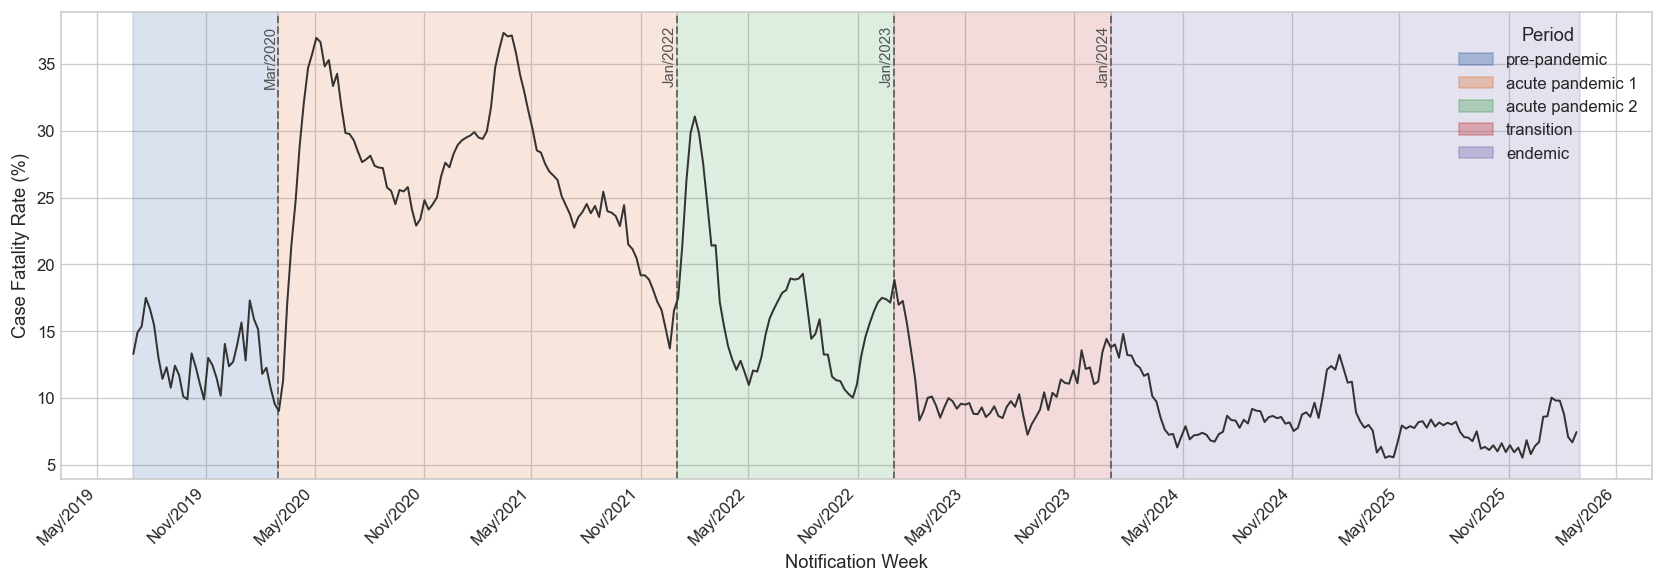

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\artigo\fig02_age_period.png


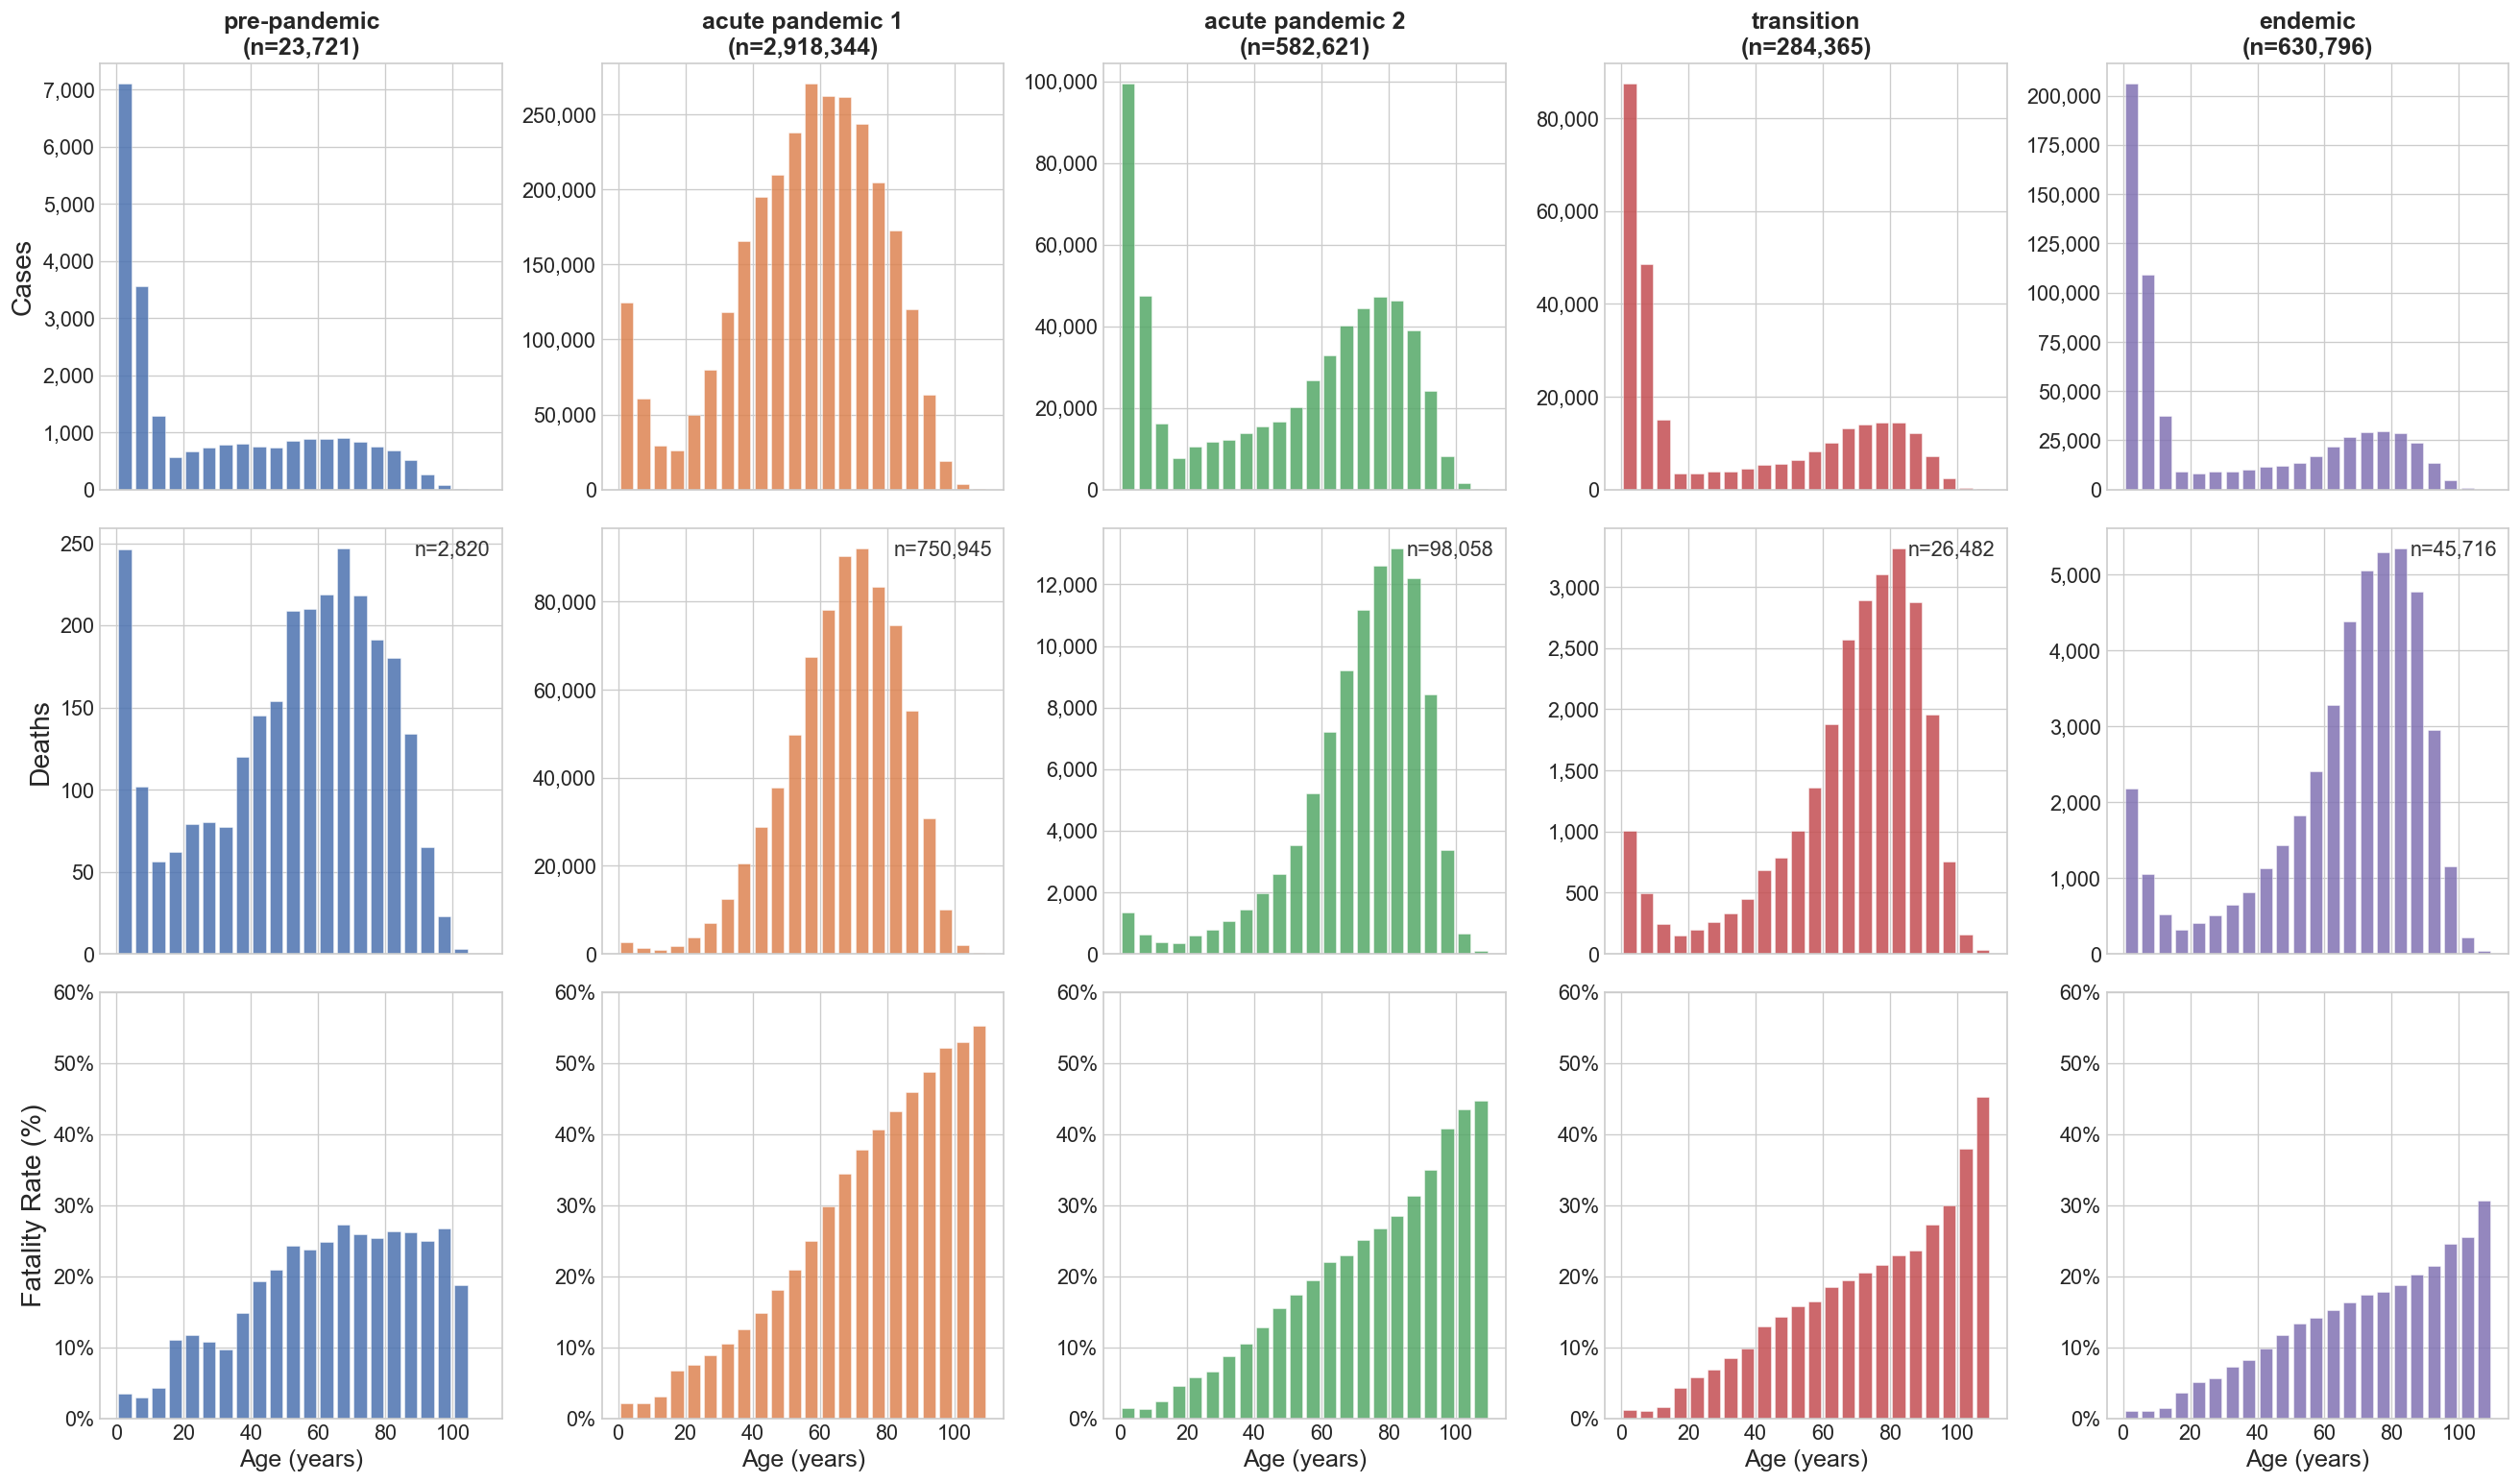

In [5]:
def plot_fig01(srag):
    """Fig. 1 — série temporal semanal da taxa de letalidade."""
    # count() ignora NaN → conta só desfechos definidos (EVOLUCAO 1 ou 2)
    weekly = (
        srag.groupby(srag['DT_NOTIFIC'].dt.to_period('W'))['obito']
        .agg(casos='count', obitos='sum')
        .reset_index()
    )
    weekly['letalidade'] = weekly['obitos'] / weekly['casos']
    weekly['dt'] = weekly['DT_NOTIFIC'].dt.start_time

    with plt.style.context(EDA_STYLE), plt.rc_context(EDA_RC):
        fig, ax = plt.subplots(figsize=(14, 5))
        add_period_spans(ax)
        ax.plot(weekly['dt'], weekly['letalidade'] * 100, color='#333333', linewidth=1.2, zorder=3)
        add_vlines(ax)
        fmt_xaxis(ax)
        ax.set_ylabel('Case Fatality Rate (%)')
        ax.set_xlabel('Notification Week')

        handles = [plt.Rectangle((0, 0), 1, 1, color=PERIOD_COLORS[p], alpha=0.4) for p in PERIOD_ORDER]
        ax.legend(handles, PERIOD_ORDER, loc='upper right', title='Period', framealpha=0.9)
        plt.tight_layout()
        save_fig(fig, 'fig01_cfr_temporal.png')


def plot_fig02(srag):
    """Fig. 2 — casos, óbitos e letalidade por faixa etária (5 anos) e período."""
    age_bins = np.arange(0, 113, 5)
    age_mids = age_bins[:-1] + 2.5
    bar_width = 3.8
    srag_ob = srag[srag['obito'] == True]  # noqa: E712 — coluna object com NaN

    with plt.style.context(EDA_STYLE), plt.rc_context(EDA_RC):
        fig, axes = plt.subplots(3, 5, figsize=(22, 13), sharex=True)
        for col, periodo in enumerate(PERIOD_ORDER):
            color = PERIOD_COLORS[periodo]
            bar_kw = dict(width=bar_width, color=color, alpha=0.85, edgecolor='white', linewidth=0.3)

            # ── linha 0: casos ───────────────────────────────────────────────
            ax = axes[0, col]
            sub_c = srag[srag['periodo'] == periodo]['idade'].dropna()
            counts_c, _ = np.histogram(sub_c.values, bins=age_bins)
            ax.bar(age_mids, counts_c, **bar_kw)
            ax.set_title(f'{periodo}\n(n={len(sub_c):,})', fontsize=15, fontweight='bold')
            ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x):,}'))
            ax.tick_params(axis='both', labelsize=13)

            # ── linha 1: óbitos ──────────────────────────────────────────────
            ax = axes[1, col]
            sub_o = srag_ob[srag_ob['periodo'] == periodo]['idade'].dropna()
            counts_o, _ = np.histogram(sub_o.values, bins=age_bins)
            ax.bar(age_mids, counts_o, **bar_kw)
            ax.text(0.97, 0.97, f'n={len(sub_o):,}', transform=ax.transAxes,
                    ha='right', va='top', fontsize=13, color='#333333')
            ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x):,}'))
            ax.tick_params(axis='both', labelsize=13)

            # ── linha 2: % óbitos / casos ────────────────────────────────────
            ax = axes[2, col]
            with np.errstate(invalid='ignore', divide='ignore'):
                pct = np.where(counts_c > 0, counts_o / counts_c * 100, np.nan)
            ax.bar(age_mids, pct, **bar_kw)
            ax.set_xlabel('Age (years)', fontsize=15)
            ax.set_ylim(0, 60)
            ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0f}%'))
            ax.tick_params(axis='both', labelsize=13)

        axes[0, 0].set_ylabel('Cases', fontsize=17)
        axes[1, 0].set_ylabel('Deaths', fontsize=17)
        axes[2, 0].set_ylabel('Fatality Rate (%)', fontsize=17)
        plt.tight_layout()
        save_fig(fig, 'fig02_age_period.png')


if RUN_EDA:
    srag = load_srag()
    plot_fig01(srag)
    plot_fig02(srag)
    del srag
else:
    print('RUN_EDA = False — Figs. 1–2 puladas')

### Fig. 3 — Vanilla LR sob distribution shift

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\artigo\fig03_vanilla_lr.png


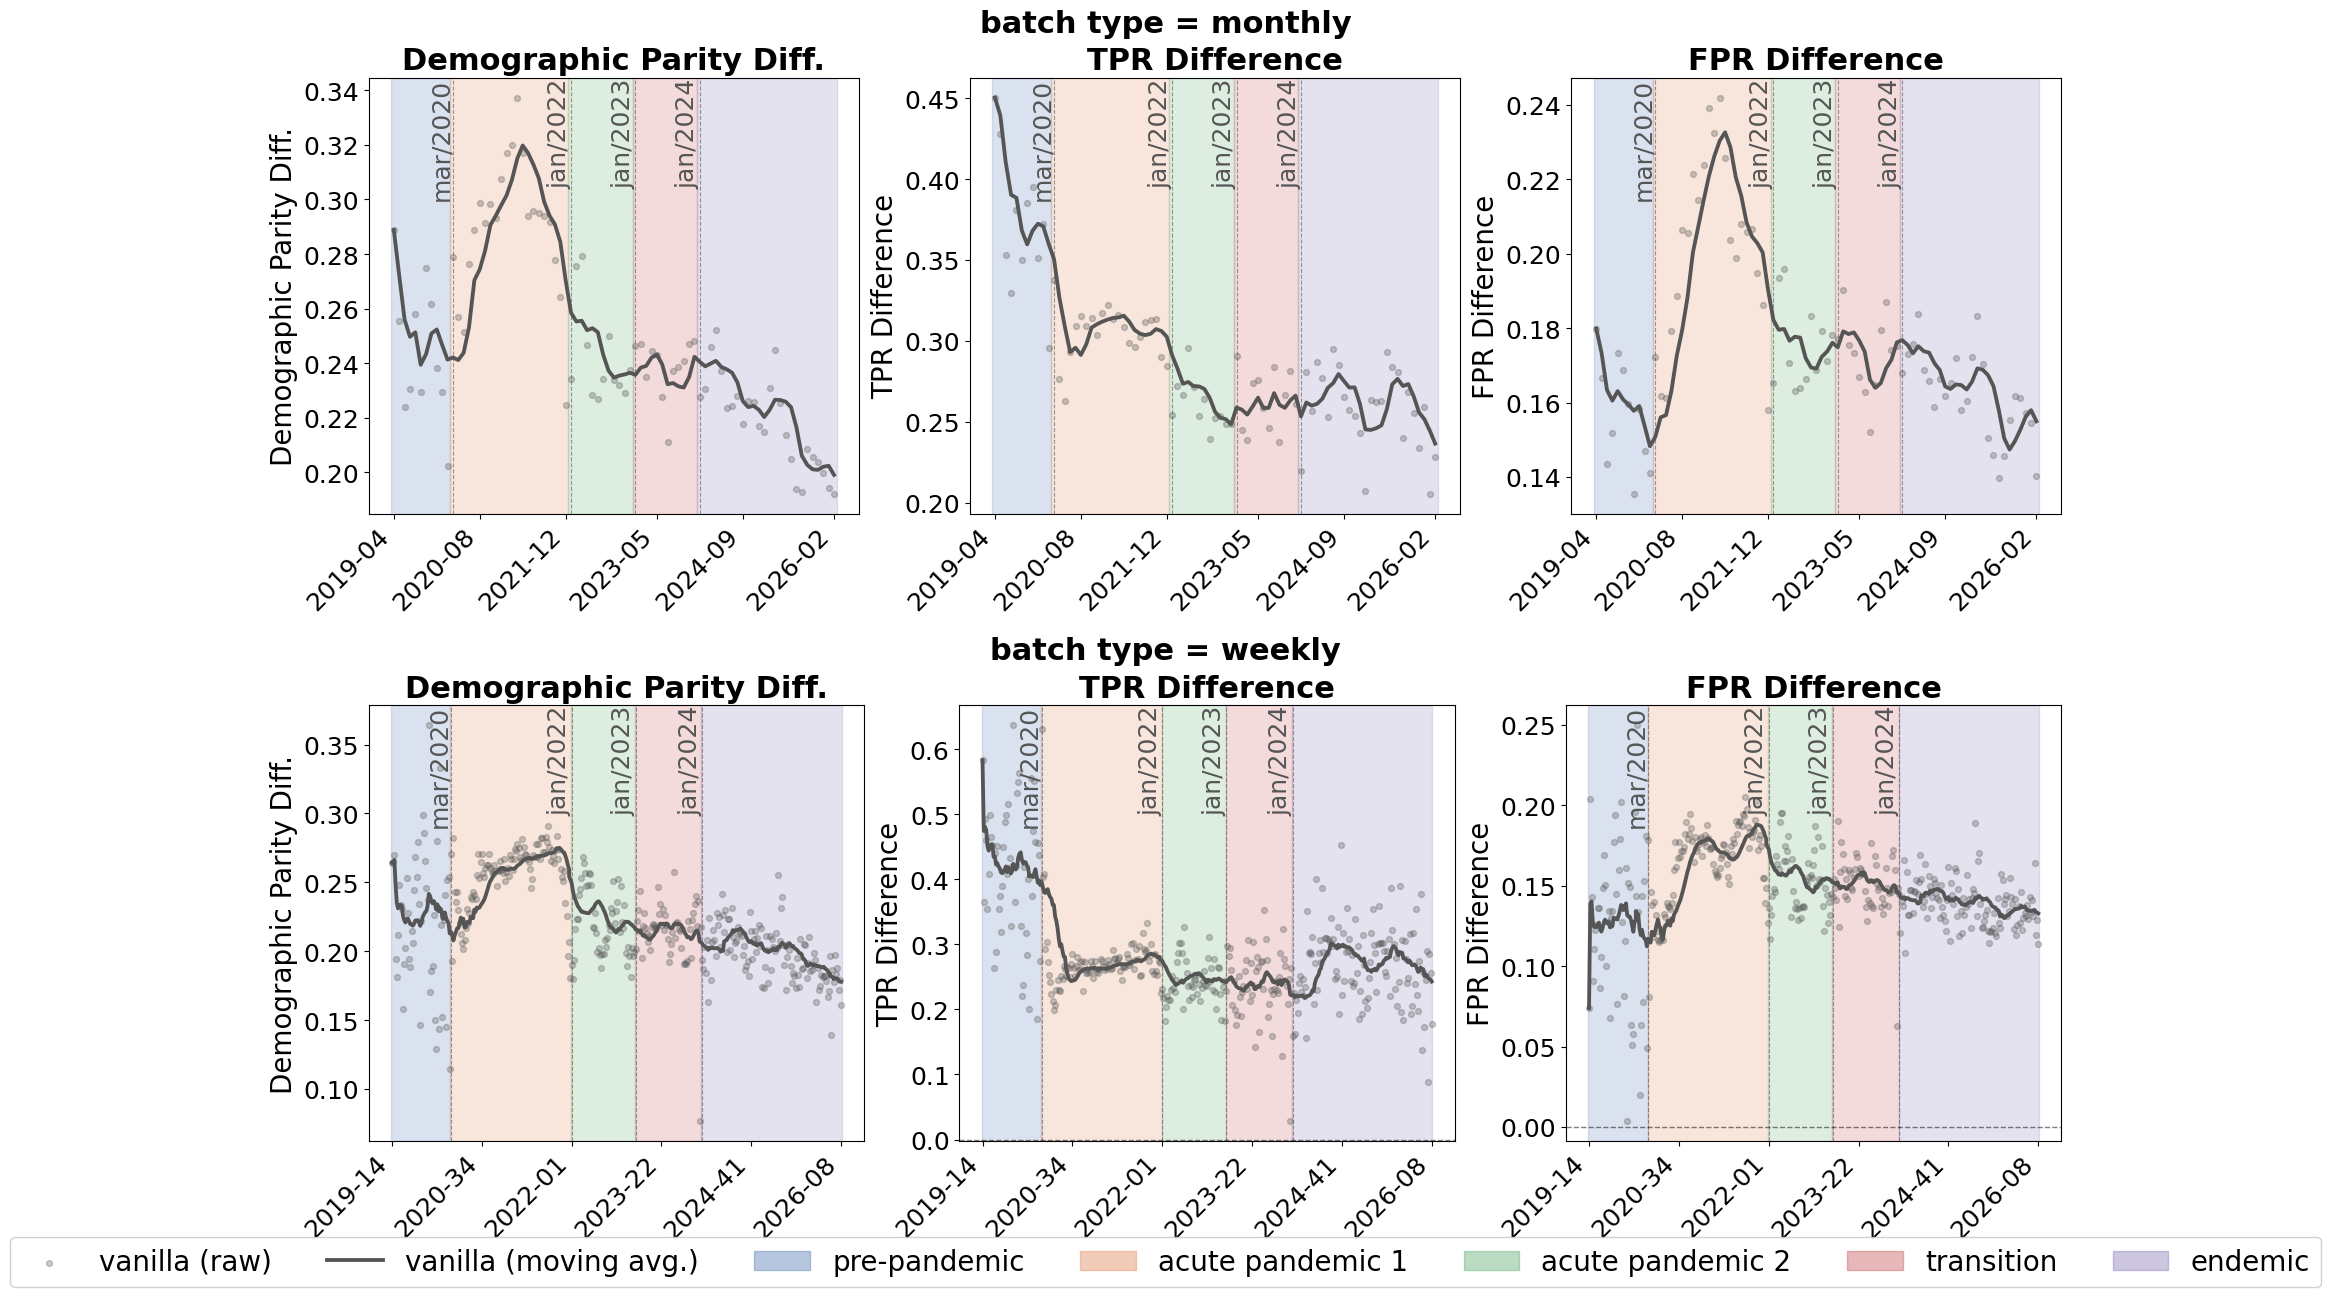

In [6]:
# Mesma função usada pela CLI src/tools/vanilla_shift_chart.py (lê a pasta fw_3)
fig = build_chart('IDADE_BIN', 'logistic_regression', forecast_window=3)
save_fig(fig, 'fig03_vanilla_lr.png')

## 2. Logistic Regression baseline (seção 4.2)

### Fig. 4 — Comparação dos 4 baselines (LR)

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\artigo\fig04_baselines_lr.png


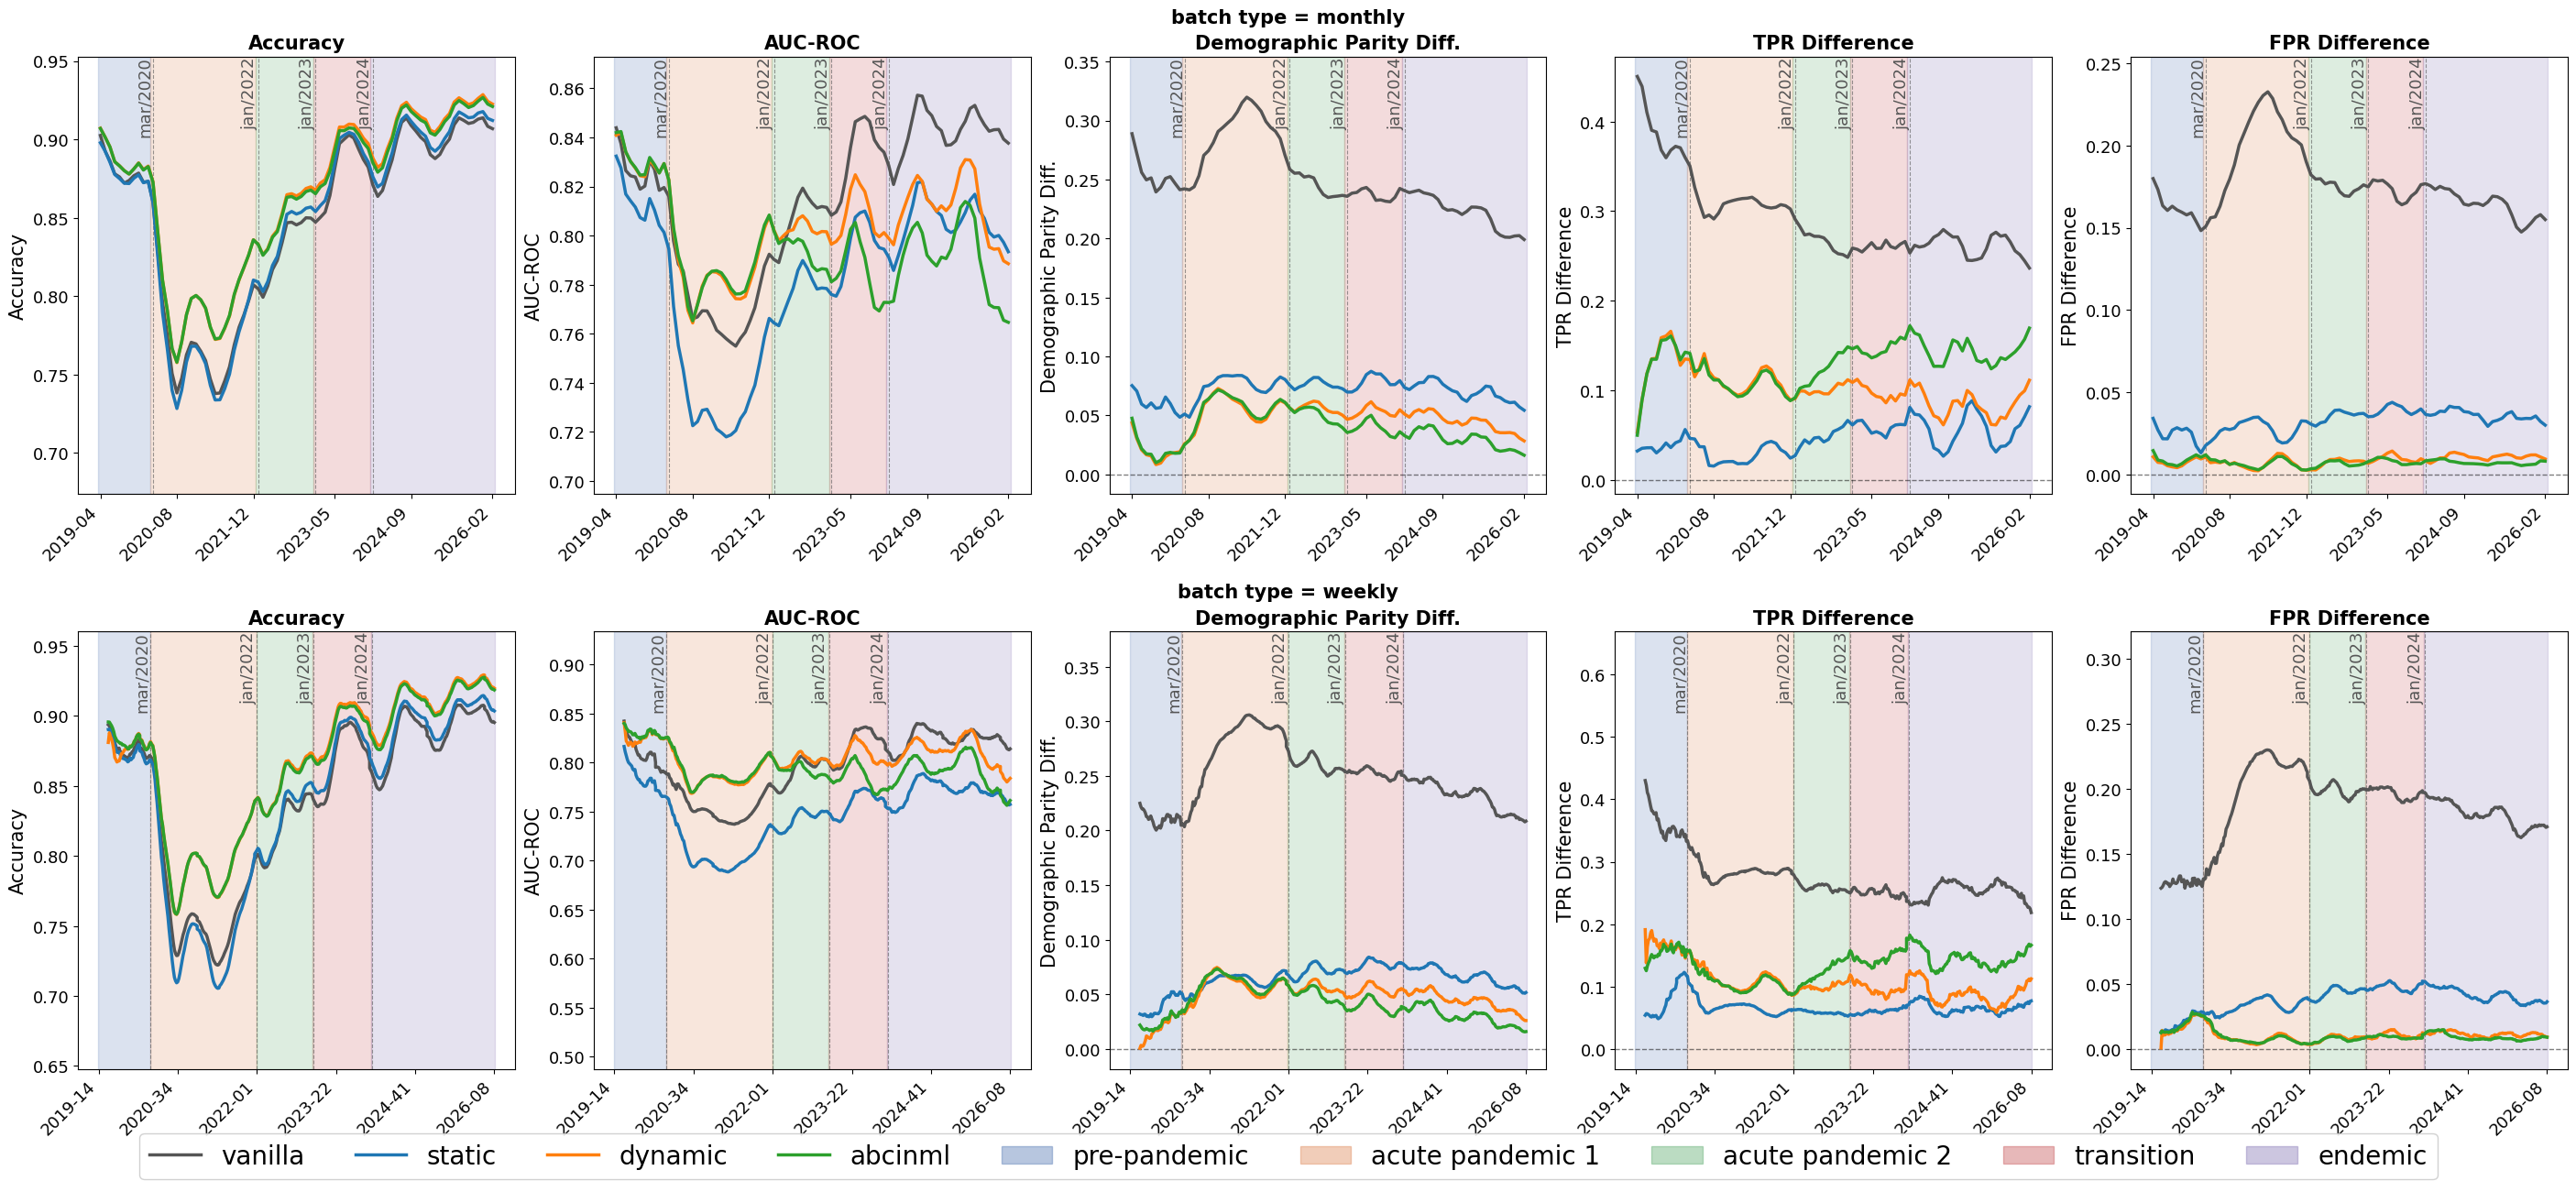

In [7]:
def plot_baselines_row(axes, df_row, batch_type, moving_avg_window):
    """Replica a lógica de _generate_comparative_chart em uma fileira de eixos."""
    df = df_row.copy()
    df['batch_dt'] = _batch_to_datetime(df['batch'].astype(str).tolist(), batch_type)
    df = df.groupby(['baseline', 'batch', 'batch_dt'], as_index=False)[metric_cols].mean()

    present_baselines = [b for b in _BASELINE_ORDER if b in df['baseline'].unique()]

    common_dates = None
    for bt in present_baselines:
        dates = set(df[df['baseline'] == bt]['batch_dt'])
        common_dates = dates if common_dates is None else common_dates & dates
    common_dates = sorted(common_dates) if common_dates else []

    metric_ylims = {}
    for col, _ in ARTICLE_METRICS:
        values = df_row[col].dropna()
        if len(values) == 0:
            continue
        vmin, vmax = values.min(), values.max()
        padding = (vmax - vmin) * 0.05
        metric_ylims[col] = (vmin - padding, vmax + padding)

    all_batch_labels = sorted(df['batch'].astype(str).unique())

    baseline_handles, period_handles = [], []
    for col_idx, (col, label) in enumerate(ARTICLE_METRICS):
        ax = axes[col_idx]

        handles = _add_period_spans(ax, all_batch_labels, batch_type)
        if not period_handles:
            period_handles = handles

        if col in ('dp', 'tpr_diff', 'fpr_diff'):
            ax.axhline(y=0, color='black', linestyle='--', linewidth=1.0, alpha=0.5, zorder=2)

        for bt in present_baselines:
            sub = df[df['baseline'] == bt]
            ma = _build_ma_series(sub, col, moving_avg_window)
            ma = ma[ma.index.isin(common_dates)] if common_dates else ma

            fmt = _BATCH_FORMAT[batch_type]
            x_pos = [all_batch_labels.index(d.strftime(fmt)) for d in ma.index if d.strftime(fmt) in all_batch_labels]
            line, = ax.plot(x_pos, ma.values, color=_BASELINE_COLORS.get(bt, None),
                            linewidth=2.5, label=bt, zorder=3)
            if col_idx == 0:
                baseline_handles.append(line)

        ax.set_title(label, fontsize=15, fontweight='bold')
        ax.set_ylabel(label, fontsize=15)
        if col in metric_ylims:
            ax.set_ylim(metric_ylims[col])
        _apply_bin_xticks(ax, all_batch_labels)
        ax.tick_params(axis='x', labelsize=13)
        ax.tick_params(axis='y', labelsize=13)

    return baseline_handles, period_handles


def plot_baselines_comparison(model_name):
    model_df = assessment_df[assessment_df['model_name'] == model_name]
    fig = plt.figure(figsize=(28, 13), layout='constrained')
    subfigs = fig.subfigures(2, 1)

    rows = [
        ('monthly', model_df[model_df['batch_type'] == 'monthly'], 5),
        ('weekly', model_df[model_df['batch_type'] == 'weekly'], 20),
    ]

    baseline_handles, period_handles = [], []
    for subfig, (batch_type, df_row, ma_window) in zip(subfigs, rows):
        axes = subfig.subplots(1, len(ARTICLE_METRICS))
        subfig.suptitle(f'batch type = {batch_type}', fontsize=15, fontweight='bold')
        bh, ph = plot_baselines_row(axes, df_row, batch_type, ma_window)
        if not baseline_handles:
            baseline_handles, period_handles = bh, ph

    # Ajustes pós-plot: alpha das faixas (mesmo da Fig. 1) e fonte dos rótulos das vlines
    for ax in fig.axes:
        for patch in ax.patches:
            patch.set_alpha(0.20)
        for text in ax.texts:
            text.set_fontsize(13)

    all_handles = baseline_handles + period_handles
    legend_labels = [PERIOD_LABELS_EN.get(h.get_label(), h.get_label()) for h in all_handles]
    leg = fig.legend(all_handles, legend_labels, loc='outside lower center',
                     ncol=len(all_handles), fontsize=20, framealpha=0.9)
    for legend_patch in leg.get_patches():
        legend_patch.set_alpha(0.4)
    return fig


save_fig(plot_baselines_comparison('logistic_regression'), 'fig04_baselines_lr.png')

### Tabela 3 — TPR/FPR absolutos por baseline e grupo (LR)

In [8]:
def absolute_rates_pivot(model_name, batch_type, as_percent=True):
    """Pivot: linhas = baseline, colunas = (TPR/FPR) × (S0/S1), média sobre os batches."""
    sub = absolute_df[
        (absolute_df['model_name'] == model_name)
        & (absolute_df['batch_type'] == batch_type)
    ]
    # média por (baseline, batch) e depois média sobre os batches
    per_batch = sub.groupby(['baseline', 'batch'], as_index=False)[rate_cols].mean()
    agg = (
        per_batch.groupby('baseline')[rate_cols].mean()
        .reindex([b for b in _BASELINE_ORDER if b in per_batch['baseline'].unique()])
    )
    piv = pd.DataFrame({
        ('TPR', 'S0 (privileged)'): agg['tpr_S0'],
        ('TPR', 'S1 (sensitive)'): agg['tpr_S1'],
        ('FPR', 'S0 (privileged)'): agg['fpr_S0'],
        ('FPR', 'S1 (sensitive)'): agg['fpr_S1'],
    })
    piv.columns = pd.MultiIndex.from_tuples(piv.columns, names=['Metric', 'Group'])
    piv.index.name = 'Baseline'
    if as_percent:
        piv = piv * 100
    return piv.round(2)


def pivot_table_latex(model_name, model_label, label):
    """Pivot TPR/FPR em LaTeX (booktabs); blocos monthly e weekly."""
    lines = [
        r'\begin{table}',
        rf'  \caption{{Mean TPR and FPR by Baseline and Group - {model_label}.}}',
        rf'  \label{{{label}}}',
        r'  \begin{tabular}{lrrrr}',
        r'    \toprule',
        r'     & \multicolumn{2}{c}{TPR} & \multicolumn{2}{c}{FPR} \\',
        r'    \cmidrule(lr){2-3} \cmidrule(lr){4-5}',
        r'    Baseline & S0 (privileged) & S1 (sensitive) & S0 (privileged) & S1 (sensitive) \\',
    ]
    for batch_type in ('monthly', 'weekly'):
        piv = absolute_rates_pivot(model_name, batch_type)
        lines += [
            r'    \midrule',
            rf'    \multicolumn{{5}}{{c}}{{\textit{{batch type = {batch_type}}}}} \\',
            r'    \midrule',
        ]
        for baseline, row in zip(piv.index, piv.values):
            lines.append(f'    {baseline} & ' + ' & '.join(rf'{v:.2f}\%' for v in row) + r' \\')
    lines += [r'    \bottomrule', r'  \end{tabular}', r'\end{table}']
    return save_tex(lines, f'tab03_absolute_rates_{MODEL_ABBR[model_name]}.tex')


print(pivot_table_latex('logistic_regression', 'Logistic Regression', 'tab:absolute-rates-lr'))
pd.concat({bt: absolute_rates_pivot('logistic_regression', bt) for bt in ('monthly', 'weekly')})

Tabela salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\artigo\tab03_absolute_rates_lr.tex
\begin{table}
  \caption{Mean TPR and FPR by Baseline and Group - Logistic Regression.}
  \label{tab:absolute-rates-lr}
  \begin{tabular}{lrrrr}
    \toprule
     & \multicolumn{2}{c}{TPR} & \multicolumn{2}{c}{FPR} \\
    \cmidrule(lr){2-3} \cmidrule(lr){4-5}
    Baseline & S0 (privileged) & S1 (sensitive) & S0 (privileged) & S1 (sensitive) \\
    \midrule
    \multicolumn{5}{c}{\textit{batch type = monthly}} \\
    \midrule
    vanilla & 20.19\% & 48.86\% & 2.22\% & 19.75\% \\
    static & 32.98\% & 28.69\% & 4.35\% & 7.52\% \\
    dynamic & 37.58\% & 27.31\% & 3.73\% & 4.28\% \\
    abcinml & 39.21\% & 25.97\% & 3.93\% & 4.03\% \\
    \midrule
    \multicolumn{5}{c}{\textit{batch type = weekly}} \\
    \midrule
    vanilla & 20.48\% & 47.68\% & 2.94\% & 21.38\% \\
    static & 25.97\% & 23.08\% & 4.29\% & 7.81\% \\
    dynamic & 37.72\% & 27.47\% & 3.77\% & 4.32\% \\

Metric                       TPR                            FPR               
Group            S0 (privileged) S1 (sensitive) S0 (privileged) S1 (sensitive)
        Baseline                                                              
monthly vanilla            20.19          48.86            2.22          19.75
        static             32.98          28.69            4.35           7.52
        dynamic            37.58          27.31            3.73           4.28
        abcinml            39.21          25.97            3.93           4.03
weekly  vanilla            20.48          47.68            2.94          21.38
        static             25.97          23.08            4.29           7.81
        dynamic            37.72          27.47            3.77           4.32
        abcinml            39.07          25.93            3.94           4.03

#### Tabela 3b — versão combinada (média de monthly e weekly)

In [9]:
def absolute_rates_pooled(model_name):
    """Média, célula a célula, das pivots monthly e weekly (pesos iguais por batch type)."""
    return ((absolute_rates_pivot(model_name, 'monthly') + absolute_rates_pivot(model_name, 'weekly')) / 2).round(2)


def pooled_pivot_latex(model_name, model_label, label):
    lines = [
        r'\begin{table}',
        rf'  \caption{{Mean TPR and FPR by Baseline and Group, averaged over monthly and weekly batches - {model_label}.}}',
        rf'  \label{{{label}}}',
        r'  \begin{tabular}{lrrrr}',
        r'    \toprule',
        r'     & \multicolumn{2}{c}{TPR} & \multicolumn{2}{c}{FPR} \\',
        r'    \cmidrule(lr){2-3} \cmidrule(lr){4-5}',
        r'    Baseline & S0 (privileged) & S1 (sensitive) & S0 (privileged) & S1 (sensitive) \\',
        r'    \midrule',
    ]
    piv = absolute_rates_pooled(model_name)
    for baseline, row in zip(piv.index, piv.values):
        lines.append(f'    {baseline} & ' + ' & '.join(rf'{v:.2f}\%' for v in row) + r' \\')
    lines += [r'    \bottomrule', r'  \end{tabular}', r'\end{table}']
    return save_tex(lines, f'tab03b_absolute_rates_{MODEL_ABBR[model_name]}_combined.tex')


print(pooled_pivot_latex('logistic_regression', 'Logistic Regression', 'tab:absolute-rates-lr-combined'))
absolute_rates_pooled('logistic_regression')

Tabela salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\artigo\tab03b_absolute_rates_lr_combined.tex
\begin{table}
  \caption{Mean TPR and FPR by Baseline and Group, averaged over monthly and weekly batches - Logistic Regression.}
  \label{tab:absolute-rates-lr-combined}
  \begin{tabular}{lrrrr}
    \toprule
     & \multicolumn{2}{c}{TPR} & \multicolumn{2}{c}{FPR} \\
    \cmidrule(lr){2-3} \cmidrule(lr){4-5}
    Baseline & S0 (privileged) & S1 (sensitive) & S0 (privileged) & S1 (sensitive) \\
    \midrule
    vanilla & 20.34\% & 48.27\% & 2.58\% & 20.56\% \\
    static & 29.48\% & 25.88\% & 4.32\% & 7.66\% \\
    dynamic & 37.65\% & 27.39\% & 3.75\% & 4.30\% \\
    abcinml & 39.14\% & 25.95\% & 3.94\% & 4.03\% \\
    \bottomrule
  \end{tabular}
\end{table}


Metric               TPR                            FPR               
Group    S0 (privileged) S1 (sensitive) S0 (privileged) S1 (sensitive)
Baseline                                                              
vanilla            20.34          48.27            2.58          20.56
static             29.48          25.88            4.32           7.66
dynamic            37.65          27.39            3.75           4.30
abcinml            39.14          25.95            3.94           4.03

### Tabela 4 — Variação de α no ABCInML (LR, monthly)

In [10]:
ALPHA_HEADERS = {
    'acc': r'Accuracy $\uparrow$',
    'auc': r'AUC-ROC $\uparrow$',
    'dp': r'DP Diff. $\downarrow$',
    'tpr_diff': r'TPR Diff. $\downarrow$',
    'fpr_diff': r'FPR Diff. $\downarrow$',
}
PERF_METRICS = {'acc', 'auc'}  # maior é melhor; as de fairness, menor é melhor


def alpha_table(model_name, batch_type='monthly', as_percent=True):
    """Linhas = alpha, colunas = métricas snapshot; média sobre os batches do abcinml."""
    abc = assessment_df[
        (assessment_df['model_name'] == model_name)
        & (assessment_df['batch_type'] == batch_type)
        & (assessment_df['baseline'] == 'abcinml')
    ]
    tbl = abc.groupby('alpha')[metric_cols].mean().sort_index()
    return (tbl * 100 if as_percent else tbl).round(2)


def alpha_table_latex(model_name, model_label, label, batch_type='monthly'):
    """Tabela no estilo da Tabela 4 do artigo: bandas Performance/Fairness, melhor valor em negrito."""
    tbl = alpha_table(model_name, batch_type)
    n_perf = sum(c in PERF_METRICS for c in metric_cols)
    n_fair = len(metric_cols) - n_perf
    header = ' & '.join([r'$\alpha$'] + [ALPHA_HEADERS[c] for c in metric_cols])
    lines = [
        r'\begin{table}',
        rf'  \caption{{ABCInML alpha parameter variation - {model_label}.}}',
        rf'  \label{{{label}}}',
        r'  \begin{tabular}{l' + 'r' * len(metric_cols) + '}',
        r'    \toprule',
        rf'     & \multicolumn{{{n_perf}}}{{c}}{{Performance}} & \multicolumn{{{n_fair}}}{{c}}{{Fairness}} \\',
        rf'    \cmidrule(lr){{2-{1 + n_perf}}} \cmidrule(lr){{{2 + n_perf}-{1 + len(metric_cols)}}}',
        rf'    {header} \\',
        r'    \midrule',
    ]
    best = {c: (tbl[c].max() if c in PERF_METRICS else tbl[c].min()) for c in metric_cols}
    for alpha, row in tbl.iterrows():
        cells = [
            rf'\textbf{{{v:.2f}\%}}' if v == best[col] else rf'{v:.2f}\%'
            for col, v in row.items()
        ]
        lines.append(f'    {alpha:.1f} & ' + ' & '.join(cells) + r' \\')
    lines += [r'    \bottomrule', r'  \end{tabular}', r'\end{table}']
    return save_tex(lines, f'tab04_alpha_{MODEL_ABBR[model_name]}.tex')


print(alpha_table_latex('logistic_regression', 'Logistic Regression', 'tab:alpha-lr'))
alpha_table('logistic_regression')

Tabela salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\artigo\tab04_alpha_lr.tex
\begin{table}
  \caption{ABCInML alpha parameter variation - Logistic Regression.}
  \label{tab:alpha-lr}
  \begin{tabular}{lrrrrr}
    \toprule
     & \multicolumn{2}{c}{Performance} & \multicolumn{3}{c}{Fairness} \\
    \cmidrule(lr){2-3} \cmidrule(lr){4-6}
    $\alpha$ & Accuracy $\uparrow$ & AUC-ROC $\uparrow$ & DP Diff. $\downarrow$ & TPR Diff. $\downarrow$ & FPR Diff. $\downarrow$ \\
    \midrule
    0.0 & 86.49\% & 77.80\% & \textbf{3.22\%} & 16.39\% & 0.88\% \\
    0.1 & 86.51\% & 78.10\% & 3.35\% & 15.72\% & 0.80\% \\
    0.2 & 86.54\% & 78.38\% & 3.50\% & 15.07\% & 0.71\% \\
    0.3 & 86.56\% & 78.65\% & 3.65\% & 14.50\% & 0.66\% \\
    0.4 & 86.59\% & 78.91\% & 3.81\% & 13.86\% & 0.62\% \\
    0.5 & 86.61\% & 79.16\% & 3.97\% & 13.25\% & \textbf{0.60\%} \\
    0.6 & 86.64\% & 79.40\% & 4.13\% & 12.67\% & 0.61\% \\
    0.7 & 86.66\% & 79.63\% & 4.29\% & 12.04\% & 0.64

,acc,auc,dp,tpr_diff,fpr_diff
alpha,,,,,
0.0,86.49,77.80,3.22,16.39,0.88
0.1,86.51,78.10,3.35,15.72,0.80
0.2,86.54,78.38,3.50,15.07,0.71
0.3,86.56,78.65,3.65,14.50,0.66
0.4,86.59,78.91,3.81,13.86,0.62
0.5,86.61,79.16,3.97,13.25,0.60
0.6,86.64,79.40,4.13,12.67,0.61
0.7,86.66,79.63,4.29,12.04,0.64
0.8,86.68,79.85,4.45,11.41,0.70


### Tabela 5 — Métricas temporais por baseline (LR)

In [11]:
TEMPORAL_METRICS = ['Maximum Bias', 'Temporal Stability', 'Maximum Bias Difference']
# Cabeçalhos do LaTeX: ↓ = menor é melhor (as três temporais são ↓)
TEMPORAL_HEADERS = [r'Max. Bias $\downarrow$', r'Temporal Stability $\downarrow$', r'Max. Bias Diff. $\downarrow$']
TABLE_WINDOW = {'monthly': 3, 'weekly': 5}  # única janela com os 4 baselines em cada batch_type


def temporal_metrics_table(model_name, batch_type, as_percent=True):
    """Linhas = baseline, colunas = métricas temporais; abcinml = média sobre os alphas."""
    fw = TABLE_WINDOW[batch_type]
    sub = temporal_df[
        (temporal_df['model_name'] == model_name)
        & (temporal_df['batch_type'] == batch_type)
        & (temporal_df['forecast_window'] == fw)
    ]
    missing = [b for b in _BASELINE_ORDER if b not in sub['baseline'].unique()]
    assert not missing, f'{model_name} {batch_type} fw={fw}: faltam {missing}'
    tbl = sub.groupby('baseline')[TEMPORAL_METRICS].mean().reindex(_BASELINE_ORDER)
    tbl.index.name = 'Baseline'
    return (tbl * 100 if as_percent else tbl).round(2)


def temporal_rows_latex(tbl, batch_type):
    """Bloco de um batch_type, com o melhor (menor) valor de cada coluna em negrito."""
    lines = [
        r'    \midrule',
        rf'    \multicolumn{{4}}{{c}}{{\textit{{batch type = {batch_type}, forecast window = {TABLE_WINDOW[batch_type]}}}}} \\',
        r'    \midrule',
    ]
    for name, row in tbl.iterrows():
        cells = [
            rf'\textbf{{{v:.2f}\%}}' if v == tbl[col].min() else rf'{v:.2f}\%'
            for col, v in row.items()
        ]
        lines.append(f'    {name} & ' + ' & '.join(cells) + r' \\')
    return lines


def temporal_table_latex(model_name, model_label, label):
    header = ' & '.join(['Baseline', *TEMPORAL_HEADERS])
    lines = [
        r'\begin{table}',
        rf'  \caption{{Temporal Fairness Metrics by Baseline - {model_label}.}}',
        rf'  \label{{{label}}}',
        r'  \begin{tabular}{lrrr}',
        r'    \toprule',
        rf'    {header} \\',
    ]
    for batch_type in ('monthly', 'weekly'):
        lines += temporal_rows_latex(temporal_metrics_table(model_name, batch_type), batch_type)
    lines += [r'    \bottomrule', r'  \end{tabular}', r'\end{table}']
    return save_tex(lines, f'tab05_temporal_{MODEL_ABBR[model_name]}.tex')


print(temporal_table_latex('logistic_regression', 'Logistic Regression', 'tab:temporal-lr'))
pd.concat({bt: temporal_metrics_table('logistic_regression', bt) for bt in ('monthly', 'weekly')})

Tabela salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\artigo\tab05_temporal_lr.tex
\begin{table}
  \caption{Temporal Fairness Metrics by Baseline - Logistic Regression.}
  \label{tab:temporal-lr}
  \begin{tabular}{lrrr}
    \toprule
    Baseline & Max. Bias $\downarrow$ & Temporal Stability $\downarrow$ & Max. Bias Diff. $\downarrow$ \\
    \midrule
    \multicolumn{4}{c}{\textit{batch type = monthly, forecast window = 3}} \\
    \midrule
    vanilla & 33.73\% & 1.29\% & 7.66\% \\
    static & 10.10\% & 1.14\% & 6.19\% \\
    dynamic & \textbf{8.25\%} & \textbf{0.99\%} & \textbf{4.78\%} \\
    abcinml & 9.13\% & 1.17\% & 5.00\% \\
    \midrule
    \multicolumn{4}{c}{\textit{batch type = weekly, forecast window = 5}} \\
    \midrule
    vanilla & 36.42\% & 1.95\% & 24.94\% \\
    static & 18.12\% & 1.55\% & 10.99\% \\
    dynamic & 10.97\% & 1.13\% & \textbf{8.14\%} \\
    abcinml & \textbf{9.95\%} & \textbf{1.12\%} & 8.65\% \\
    \bottomrule
  \end{tabula

Maximum Bias  Temporal Stability  Maximum Bias Difference
        Baseline                                                           
monthly vanilla          33.73                1.29                     7.66
        static           10.10                1.14                     6.19
        dynamic           8.25                0.99                     4.78
        abcinml           9.13                1.17                     5.00
weekly  vanilla          36.42                1.95                    24.94
        static           18.12                1.55                    10.99
        dynamic          10.97                1.13                     8.14
        abcinml           9.95                1.12                     8.65

#### Tabela 5b — versão combinada (monthly e weekly lado a lado)

In [12]:
print(temporal_side_by_side_latex(
    {bt: temporal_metrics_table('logistic_regression', bt) for bt in BT_ORDER},
    'Baseline', 'Temporal Fairness Metrics by Baseline - Logistic Regression.',
    'tab:temporal-lr-combined', 'tab05b_temporal_lr_combined.tex',
))

Tabela salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\artigo\tab05b_temporal_lr_combined.tex
\begin{table}
  \small
  \caption{Temporal Fairness Metrics by Baseline - Logistic Regression. M = monthly (forecast window = 3), W = weekly (forecast window = 5).}
  \label{tab:temporal-lr-combined}
  \begin{tabular}{lrrrrrr}
    \toprule
     & \multicolumn{2}{c}{Max. Bias $\downarrow$} & \multicolumn{2}{c}{Temporal Stability $\downarrow$} & \multicolumn{2}{c}{Max. Bias Diff. $\downarrow$} \\
    \cmidrule(lr){2-3} \cmidrule(lr){4-5} \cmidrule(lr){6-7}
    Baseline & M & W & M & W & M & W \\
    \midrule
    vanilla & 33.73\% & 36.42\% & 1.29\% & 1.95\% & 7.66\% & 24.94\% \\
    static & 10.10\% & 18.12\% & 1.14\% & 1.55\% & 6.19\% & 10.99\% \\
    dynamic & \textbf{8.25\%} & 10.97\% & \textbf{0.99\%} & 1.13\% & \textbf{4.78\%} & \textbf{8.14\%} \\
    abcinml & 9.13\% & \textbf{9.95\%} & 1.17\% & \textbf{1.12\%} & 5.00\% & 8.65\% \\
    \bottomrule
  \end{tabula

## 3. Expansion to Non Linear Models (seção 4.3)

### Figs. 5–7 — Accuracy × DP / TPR / FPR variando α (LR × XGBoost × RF)

In [13]:
FRONTIER_MODELS = ['logistic_regression', 'xgboost', 'random_forest']
MODEL_COLORS = {'logistic_regression': '#1f77b4', 'xgboost': '#d62728', 'random_forest': '#2ca02c'}
MODEL_MARKERS = {'logistic_regression': 'o', 'xgboost': 's', 'random_forest': '^'}
LABEL_LANES = {'logistic_regression': (-9, 'right'), 'random_forest': (9, 'left'), 'xgboost': (62, 'left')}
METRIC_LABELS = dict(ARTICLE_METRICS)
HIGHER_IS_BETTER = {'acc', 'auc'}  # demais métricas: diferenças entre grupos, melhor perto de 0


def frontier_points(model_name, batch_type, metric):
    """Média de accuracy e da métrica (em %) por alpha, só abcinml."""
    abc = assessment_df[
        (assessment_df['model_name'] == model_name)
        & (assessment_df['batch_type'] == batch_type)
        & (assessment_df['baseline'] == 'abcinml')
    ]
    return abc.groupby('alpha')[['acc', metric]].mean().sort_index() * 100


def _underline(ax, xy, dx, dy, ha, text, color, fontsize=12):
    """Sublinha, na cor do modelo, um rótulo posicionado a (dx, dy) pontos do ponto xy (em dados)."""
    width = TextPath((0, 0), text, size=fontsize).get_extents().width  # em pontos
    x0, x1 = (dx - width, dx) if ha == 'right' else (dx, dx + width)
    # Coordenadas em pontos relativas ao ponto de dados: acompanha o layout final do savefig
    trans = (
        mtransforms.Affine2D().scale(1 / 72) + ax.figure.dpi_scale_trans
        + mtransforms.ScaledTranslation(*xy, ax.transData)
    )
    ax.add_artist(Line2D([x0, x1], [dy - 8, dy - 8], transform=trans, color=color, linewidth=2.2))


def _better_arrow(ax, axis, positive, fontsize=12):
    """Seta fora do eixo apontando para onde a métrica melhora (positive = sentido crescente)."""
    style = dict(arrowstyle='-|>', color='#555555', lw=1.8, mutation_scale=16)
    text = dict(fontsize=fontsize, color='#555555', annotation_clip=False)
    if axis == 'x':  # na linha do rótulo do eixo x, à direita
        tail, head = (0.80, -0.115), (0.97, -0.115)
        if not positive:
            tail, head = head, tail
        ax.annotate('', xy=head, xytext=tail, xycoords='axes fraction', arrowprops=style, annotation_clip=False)
        ax.annotate('better', xy=(min(tail[0], head[0]) - 0.01, -0.115), xycoords='axes fraction',
                    ha='right', va='center', **text)
    else:  # à direita do eixo y, na ponta para onde a métrica melhora
        tail, head = ((1.025, 0.62), (1.025, 0.98)) if positive else ((1.025, 0.38), (1.025, 0.02))
        ax.annotate('', xy=head, xytext=tail, xycoords='axes fraction', arrowprops=style, annotation_clip=False)
        ax.annotate('better', xy=(1.045, (tail[1] + head[1]) / 2), xycoords='axes fraction',
                    rotation=90, ha='left', va='center', **text)


def _draw_frontier(ax, batch_type, metric, points_fn=frontier_points, fs=12):
    """fs = fonte base (rótulos α e setas); eixos, ticks e legenda escalam a partir dela."""
    y_values = []
    for model in FRONTIER_MODELS:
        pts = points_fn(model, batch_type, metric)
        y_values.extend(pts[metric])
        ax.scatter(
            pts['acc'], pts[metric],
            color=MODEL_COLORS[model], marker=MODEL_MARKERS[model], s=60,
            edgecolor='white', linewidth=1.0, zorder=3, label=MODEL_LABELS[model],
        )
        # Rótulos só nas pontas (sentido de alpha); uma faixa de rótulos por modelo
        dx, ha = LABEL_LANES[model]
        a0, a1 = pts.index.min(), pts.index.max()
        # Afasta verticalmente os dois rótulos do mesmo modelo (evita encostarem quando próximos)
        away = 6 if pts.loc[a0, metric] >= pts.loc[a1, metric] else -6
        for alpha, dy in ((a0, away), (a1, -away)):
            text = f'α = {alpha:g}'
            xy = (pts.loc[alpha, 'acc'], pts.loc[alpha, metric])
            ax.annotate(text, xy, xytext=(dx, dy), textcoords='offset points', ha=ha, va='center',
                        fontsize=fs, color='#333333')
            _underline(ax, xy, dx, dy, ha, text, MODEL_COLORS[model], fontsize=fs)

    ax.margins(y=0.08)  # espaço para os rótulos das pontas
    ax.set_xlim(80, 90)  # escala fixa de accuracy, comum a todas as fronteiras
    label = METRIC_LABELS.get(metric, metric)
    ax.set_xlabel('Accuracy (%)', fontsize=fs + 3)
    ax.set_ylabel(f'{label} (%)', fontsize=fs + 3)
    ax.set_title(f'{batch_type} batches', fontsize=fs + 3, fontweight='bold')
    ax.tick_params(axis='both', labelsize=fs + 1)
    ax.grid(color='#dddddd', linewidth=0.8)
    ax.set_axisbelow(True)
    ax.legend(fontsize=fs + 1, framealpha=0.9, loc='best')

    _better_arrow(ax, 'x', positive=True, fontsize=fs)
    # Diferenças entre grupos melhoram em direção a zero: o sentido depende do sinal dos valores
    y_positive = metric in HIGHER_IS_BETTER or pd.Series(y_values).median() < 0
    _better_arrow(ax, 'y', positive=y_positive, fontsize=fs)


def plot_frontier_pair(metric):
    """Gráficos monthly e weekly da métrica lado a lado."""
    fig, axes = plt.subplots(1, 2, figsize=(21, 6), layout='constrained')
    for ax, batch_type in zip(axes, ('monthly', 'weekly')):
        _draw_frontier(ax, batch_type, metric)
    label = METRIC_LABELS.get(metric, metric)
    fig.suptitle(f'Accuracy vs. {label} across α — LR vs. XGBoost vs. RF', fontsize=17, fontweight='bold')
    return fig


pd.concat({m: frontier_points(m, 'monthly', 'dp') for m in FRONTIER_MODELS}, axis=1).round(2)

logistic_regression       xgboost       random_forest      
                      acc    dp     acc    dp           acc    dp
alpha                                                            
0.0                 86.49  3.22   86.63  2.89         86.71  2.05
0.1                 86.51  3.35   86.67  2.87         86.74  2.07
0.2                 86.54  3.50   86.70  2.86         86.76  2.08
0.3                 86.56  3.65   86.74  2.92         86.78  2.16
0.4                 86.59  3.81   86.77  3.01         86.80  2.20
0.5                 86.61  3.97   86.81  3.14         86.83  2.29
0.6                 86.64  4.13   86.84  3.31         86.85  2.32
0.7                 86.66  4.29   86.87  3.50         86.87  2.41
0.8                 86.68  4.45   86.90  3.67         86.88  2.50
0.9                 86.70  4.59   86.93  3.87         86.90  2.58
1.0                 86.73  4.75   86.98  4.14         86.92  2.74

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\artigo\fig05_frontier_dp.png


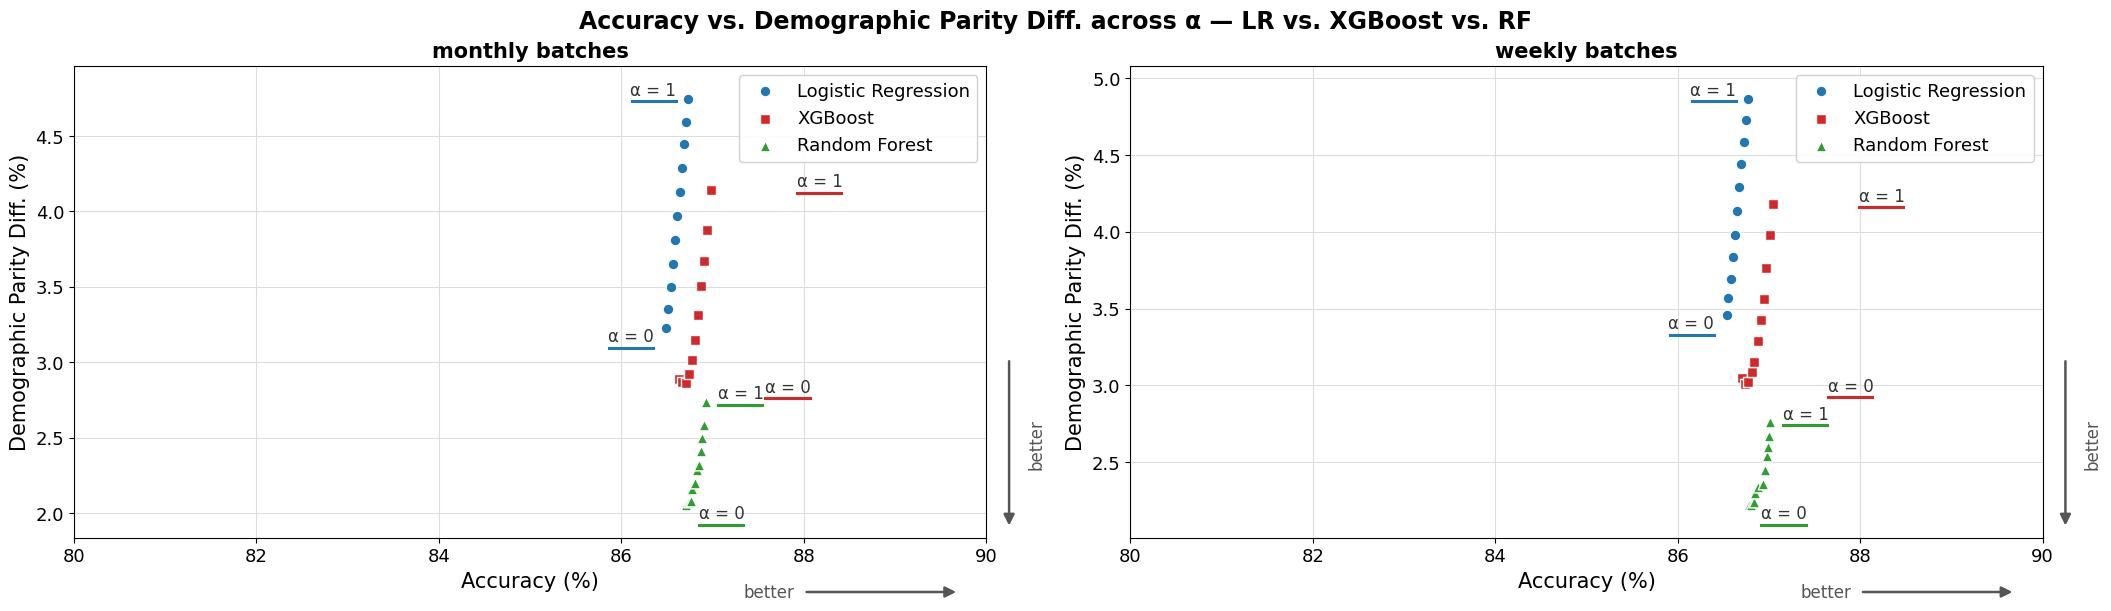

In [14]:
save_fig(plot_frontier_pair('dp'), 'fig05_frontier_dp.png')

#### Figs. 5b/6b/7b — versões combinadas (média de monthly e weekly por α)

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\artigo\fig05b_frontier_dp_combined.png


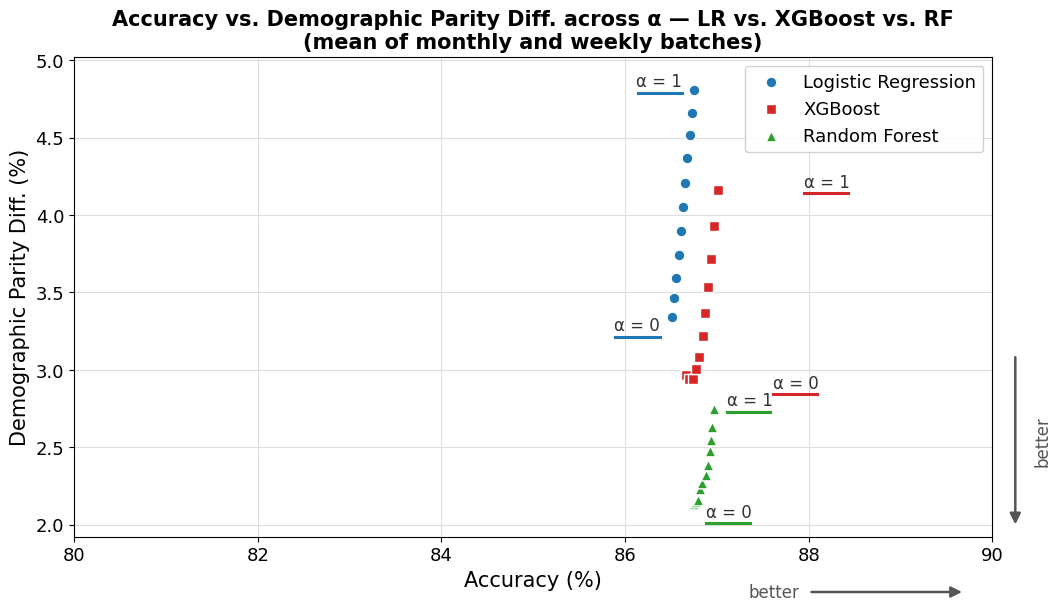

In [15]:
def frontier_points_pooled(model_name, batch_type, metric):
    """Média, por alpha, dos pontos monthly e weekly (pesos iguais; batch_type é ignorado)."""
    return (frontier_points(model_name, 'monthly', metric) + frontier_points(model_name, 'weekly', metric)) / 2


def plot_frontier_combined(metric):
    fig, ax = plt.subplots(figsize=(10.5, 6), layout='constrained')
    _draw_frontier(ax, 'combined', metric, points_fn=frontier_points_pooled)
    label = METRIC_LABELS.get(metric, metric)
    ax.set_title(f'Accuracy vs. {label} across α — LR vs. XGBoost vs. RF\n(mean of monthly and weekly batches)',
                 fontsize=15, fontweight='bold')
    return fig


save_fig(plot_frontier_combined('dp'), 'fig05b_frontier_dp_combined.png')

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\artigo\fig06_frontier_tpr.png


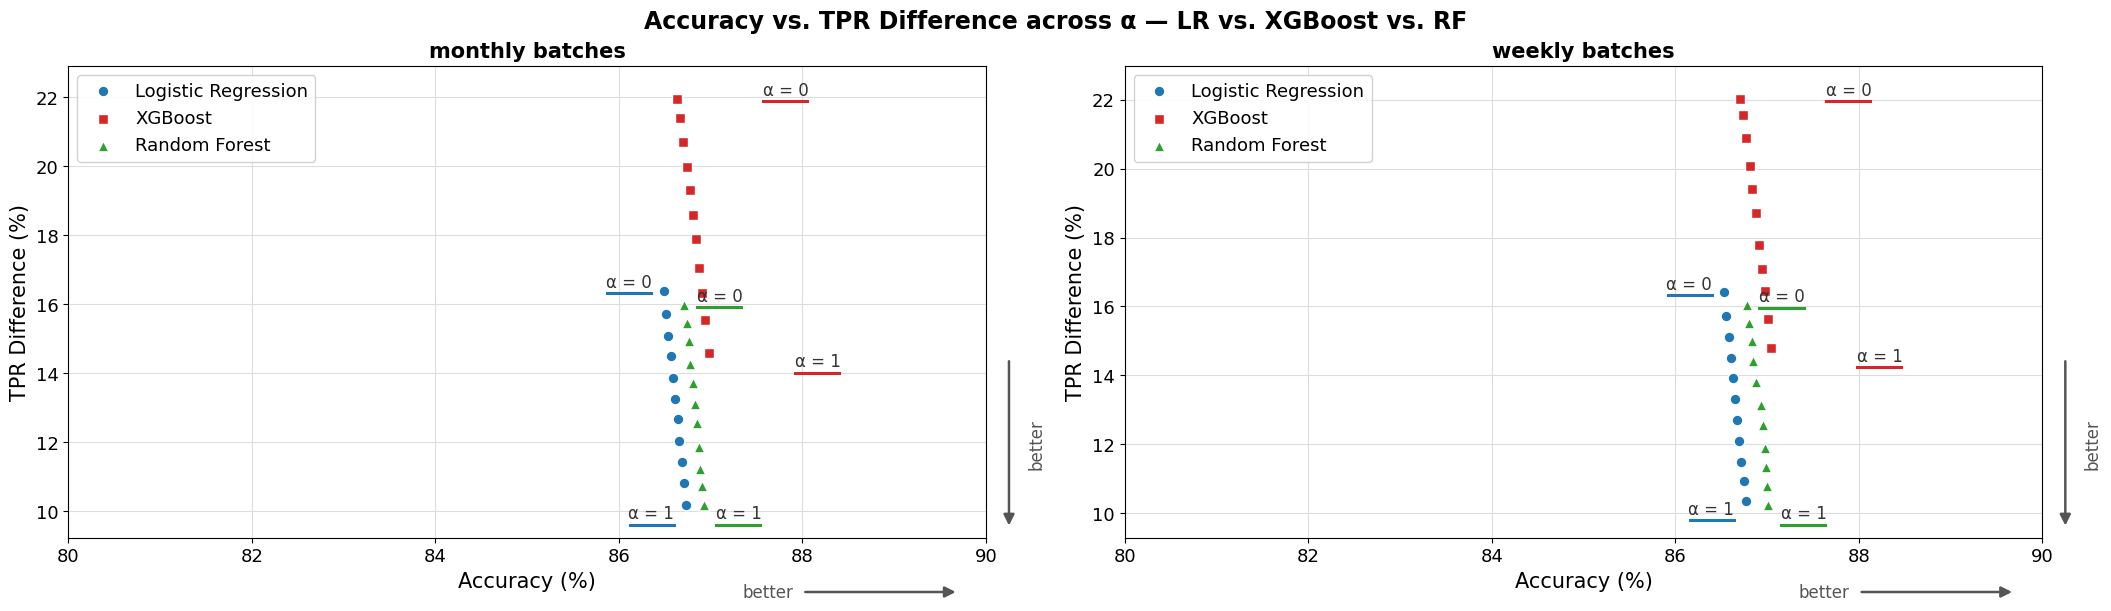

In [16]:
save_fig(plot_frontier_pair('tpr_diff'), 'fig06_frontier_tpr.png')

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\artigo\fig06b_frontier_tpr_combined.png


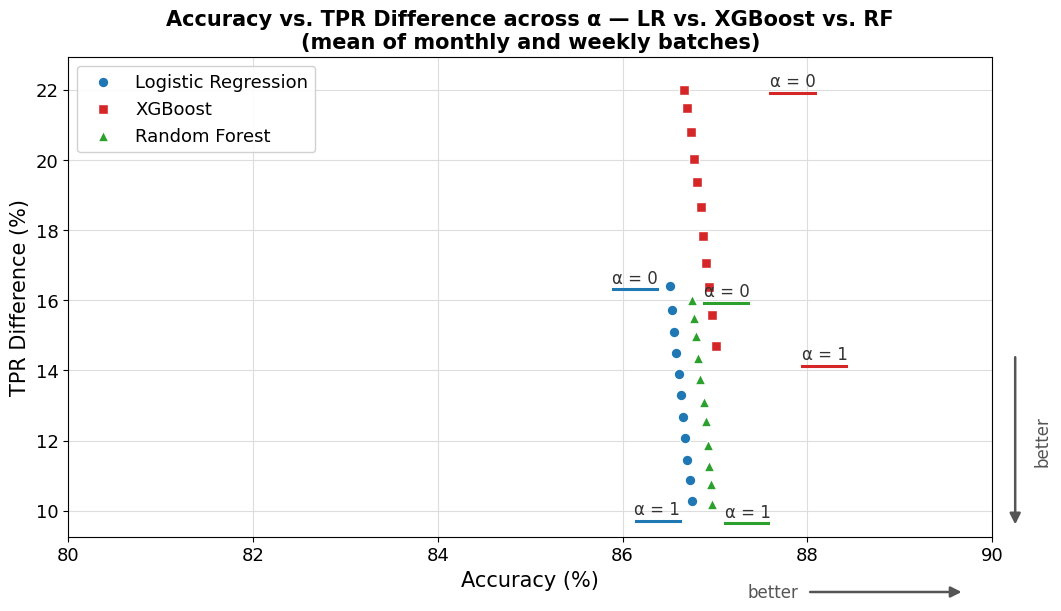

In [17]:
save_fig(plot_frontier_combined('tpr_diff'), 'fig06b_frontier_tpr_combined.png')

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\artigo\fig07_frontier_fpr.png


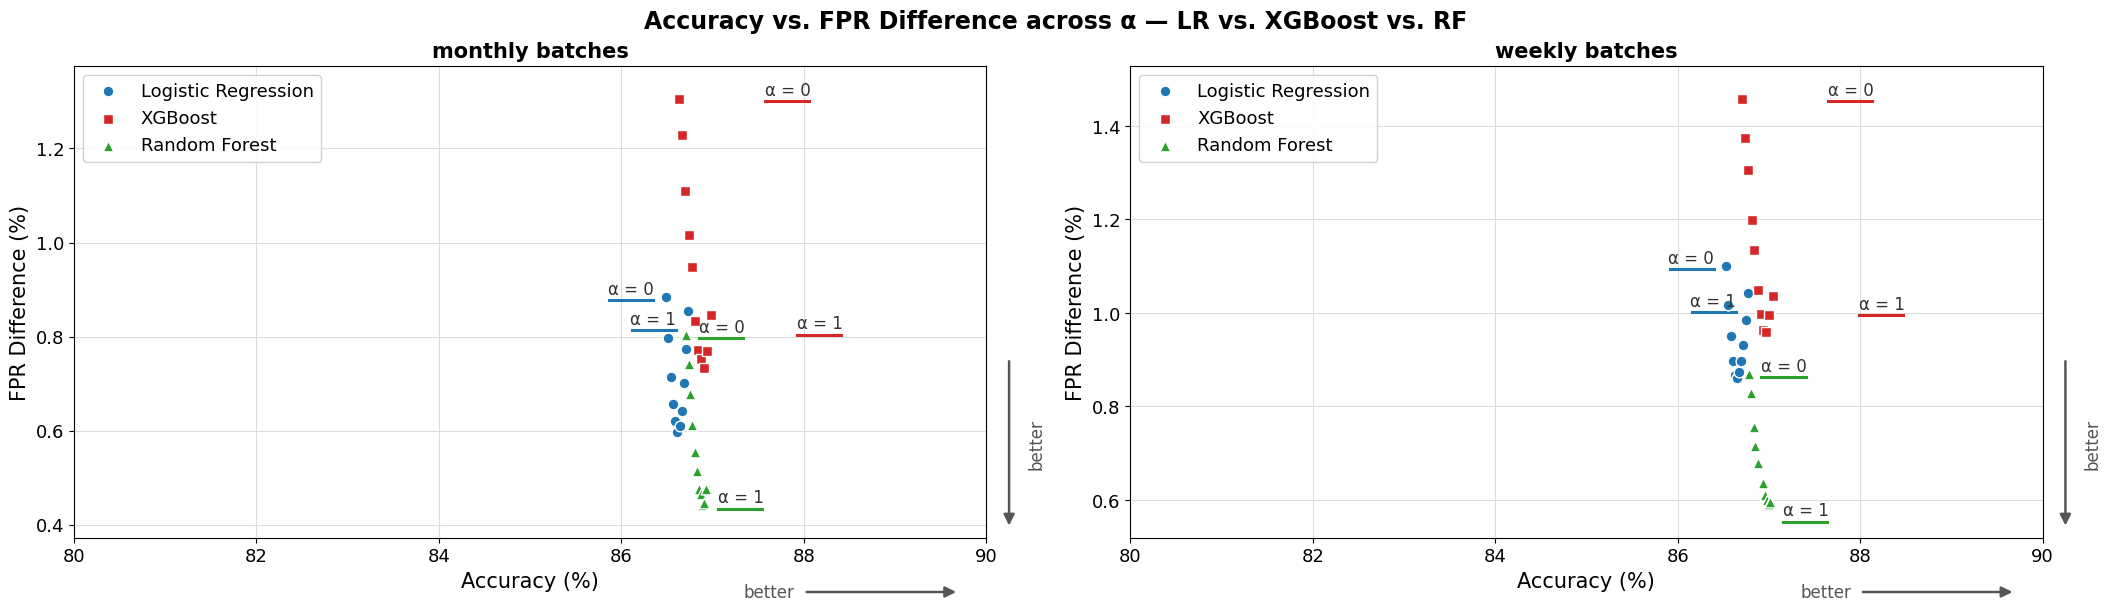

In [18]:
save_fig(plot_frontier_pair('fpr_diff'), 'fig07_frontier_fpr.png')

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\artigo\fig07b_frontier_fpr_combined.png


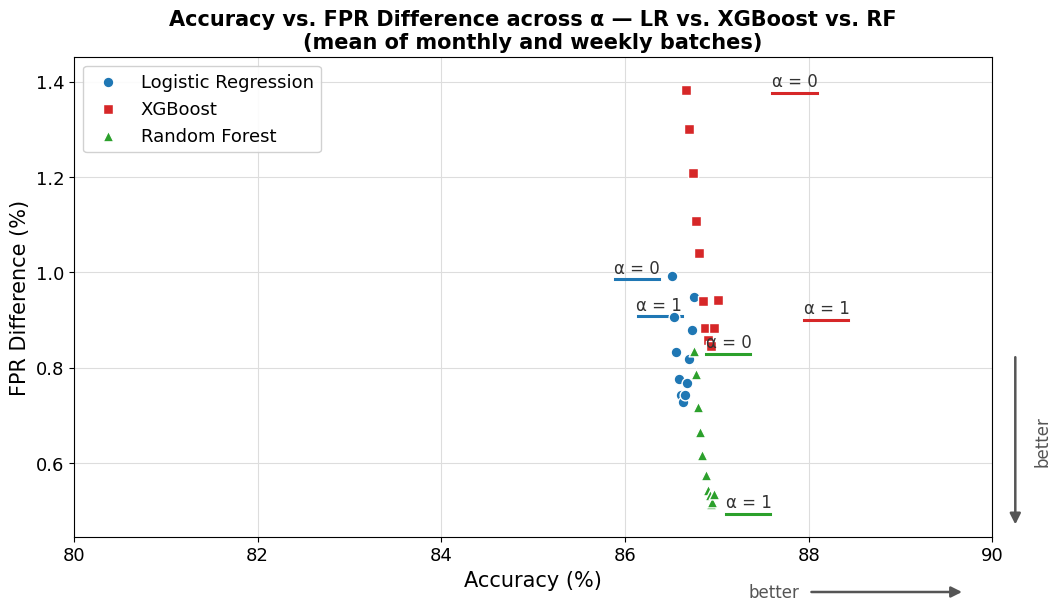

In [19]:
save_fig(plot_frontier_combined('fpr_diff'), 'fig07b_frontier_fpr_combined.png')

#### Figs. 5b/6b/7b juntas — 1×3, painéis quadrados

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\artigo\fig05c_frontier_dp_tpr_fpr_combined.png


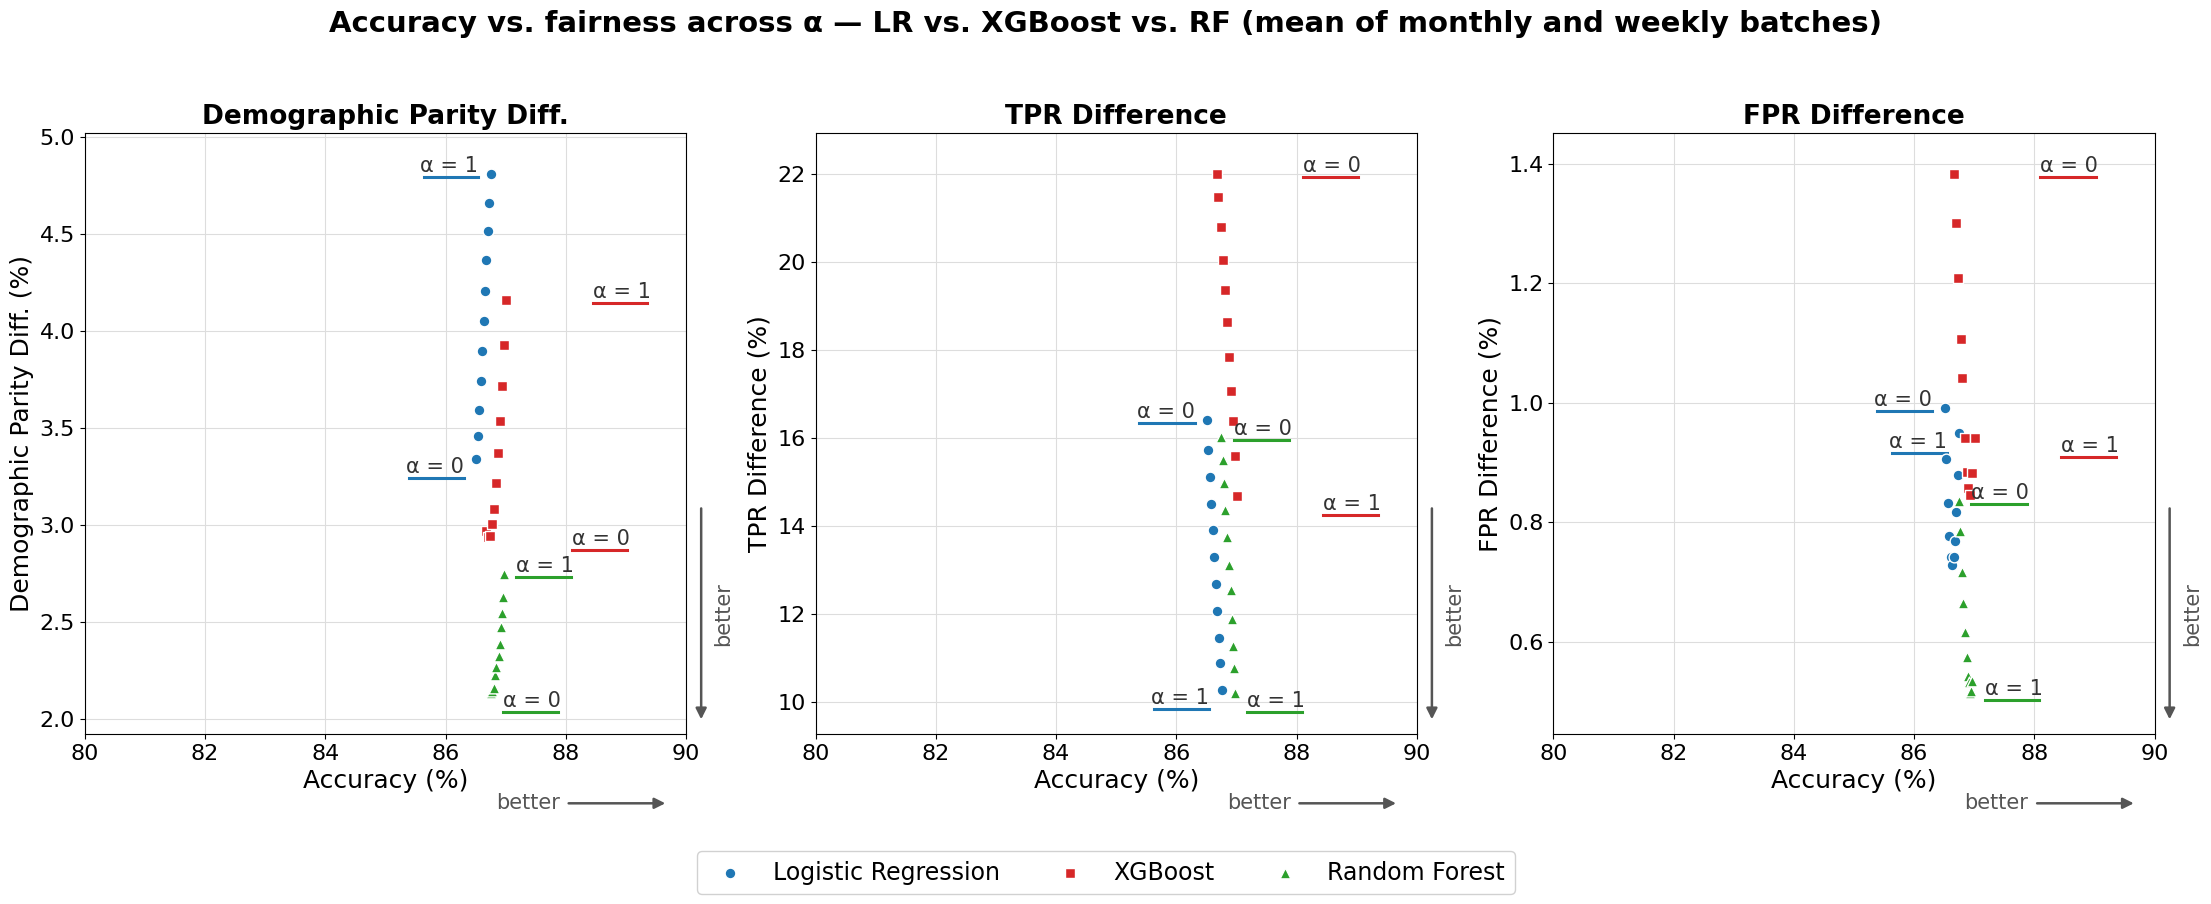

In [20]:
def plot_frontier_combined_trio(metrics=('dp', 'tpr_diff', 'fpr_diff'), fs=15):
    """Figs. 5b/6b/7b lado a lado (1×3), cada painel quadrado, com uma legenda única."""
    fig, axes = plt.subplots(1, len(metrics), figsize=(22, 9), layout='constrained')
    for ax, metric in zip(axes, metrics):
        _draw_frontier(ax, 'combined', metric, points_fn=frontier_points_pooled, fs=fs)
        ax.set_box_aspect(1)
        ax.set_title(METRIC_LABELS[metric], fontsize=fs + 4, fontweight='bold')
        ax.get_legend().remove()
    handles, labels = axes[0].get_legend_handles_labels()
    # As setas 'better' ficam fora dos eixos e o layout as ignora: reserva uma faixa no rodapé
    # para a legenda, abaixo delas (no topo ela colide com o suptitle)
    fig.get_layout_engine().set(rect=(0, 0.09, 1, 0.91))
    fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, 0), ncol=len(handles), fontsize=fs + 2, framealpha=0.9)
    fig.suptitle('Accuracy vs. fairness across α — LR vs. XGBoost vs. RF (mean of monthly and weekly batches)',
                 fontsize=fs + 6, fontweight='bold')
    return fig


save_fig(plot_frontier_combined_trio(), 'fig05c_frontier_dp_tpr_fpr_combined.png')

### Tabela 6 — Métricas temporais do ABCInML por modelo

In [21]:
def abcinml_models_table(batch_type, as_percent=True):
    """Linhas = modelo, colunas = métricas temporais do abcinml (média sobre os alphas)."""
    fw = TABLE_WINDOW[batch_type]
    sub = temporal_df[
        (temporal_df['baseline'] == 'abcinml')
        & (temporal_df['batch_type'] == batch_type)
        & (temporal_df['forecast_window'] == fw)
    ]
    n_alphas = sub.groupby('model_name')['alpha'].nunique().reindex(FRONTIER_MODELS)
    incomplete = n_alphas[n_alphas != 11]
    assert incomplete.empty, f'{batch_type} fw={fw}: alphas incompletos {incomplete.to_dict()}'
    tbl = sub.groupby('model_name')[TEMPORAL_METRICS].mean().reindex(FRONTIER_MODELS)
    tbl.index = [MODEL_LABELS[m] for m in tbl.index]
    tbl.index.name = 'Model'
    return (tbl * 100 if as_percent else tbl).round(2)


def abcinml_models_latex(label='tab:temporal-abcinml-models'):
    header = ' & '.join(['Model', *TEMPORAL_HEADERS])
    lines = [
        r'\begin{table}',
        r'  \caption{Temporal Fairness Metrics of ABCInML by Model.}',
        rf'  \label{{{label}}}',
        r'  \begin{tabular}{lrrr}',
        r'    \toprule',
        rf'    {header} \\',
    ]
    for batch_type in ('monthly', 'weekly'):
        lines += temporal_rows_latex(abcinml_models_table(batch_type), batch_type)
    lines += [r'    \bottomrule', r'  \end{tabular}', r'\end{table}']
    return save_tex(lines, 'tab06_temporal_abcinml_models.tex')


print(abcinml_models_latex())
pd.concat({bt: abcinml_models_table(bt) for bt in ('monthly', 'weekly')})

Tabela salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\artigo\tab06_temporal_abcinml_models.tex
\begin{table}
  \caption{Temporal Fairness Metrics of ABCInML by Model.}
  \label{tab:temporal-abcinml-models}
  \begin{tabular}{lrrr}
    \toprule
    Model & Max. Bias $\downarrow$ & Temporal Stability $\downarrow$ & Max. Bias Diff. $\downarrow$ \\
    \midrule
    \multicolumn{4}{c}{\textit{batch type = monthly, forecast window = 3}} \\
    \midrule
    Logistic Regression & 9.13\% & 1.17\% & 5.00\% \\
    XGBoost & 9.15\% & 1.26\% & 6.06\% \\
    Random Forest & \textbf{7.58\%} & \textbf{0.80\%} & \textbf{2.98\%} \\
    \midrule
    \multicolumn{4}{c}{\textit{batch type = weekly, forecast window = 5}} \\
    \midrule
    Logistic Regression & 9.95\% & 1.12\% & 8.65\% \\
    XGBoost & 14.40\% & 1.04\% & 10.94\% \\
    Random Forest & \textbf{7.13\%} & \textbf{0.74\%} & \textbf{4.86\%} \\
    \bottomrule
  \end{tabular}
\end{table}


Maximum Bias  Temporal Stability  \
        Model                                                   
monthly Logistic Regression          9.13                1.17   
        XGBoost                      9.15                1.26   
        Random Forest                7.58                0.80   
weekly  Logistic Regression          9.95                1.12   
        XGBoost                     14.40                1.04   
        Random Forest                7.13                0.74   

                             Maximum Bias Difference  
        Model                                         
monthly Logistic Regression                     5.00  
        XGBoost                                 6.06  
        Random Forest                           2.98  
weekly  Logistic Regression                     8.65  
        XGBoost                                10.94  
        Random Forest                           4.86

#### Tabela 6b — versão combinada (monthly e weekly lado a lado)

In [22]:
print(temporal_side_by_side_latex(
    {bt: abcinml_models_table(bt) for bt in BT_ORDER},
    'Model', 'Temporal Fairness Metrics of ABCInML by Model.',
    'tab:temporal-abcinml-models-combined', 'tab06b_temporal_abcinml_models_combined.tex',
))

Tabela salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\artigo\tab06b_temporal_abcinml_models_combined.tex
\begin{table}
  \small
  \caption{Temporal Fairness Metrics of ABCInML by Model. M = monthly (forecast window = 3), W = weekly (forecast window = 5).}
  \label{tab:temporal-abcinml-models-combined}
  \begin{tabular}{lrrrrrr}
    \toprule
     & \multicolumn{2}{c}{Max. Bias $\downarrow$} & \multicolumn{2}{c}{Temporal Stability $\downarrow$} & \multicolumn{2}{c}{Max. Bias Diff. $\downarrow$} \\
    \cmidrule(lr){2-3} \cmidrule(lr){4-5} \cmidrule(lr){6-7}
    Model & M & W & M & W & M & W \\
    \midrule
    Logistic Regression & 9.13\% & 9.95\% & 1.17\% & 1.12\% & 5.00\% & 8.65\% \\
    XGBoost & 9.15\% & 14.40\% & 1.26\% & 1.04\% & 6.06\% & 10.94\% \\
    Random Forest & \textbf{7.58\%} & \textbf{7.13\%} & \textbf{0.80\%} & \textbf{0.74\%} & \textbf{2.98\%} & \textbf{4.86\%} \\
    \bottomrule
  \end{tabular}
\end{table}


## 4. Forecasting Techniques Analysis (seção 4.4)

In [23]:
# ── Carrega e concatena os forecast_quality.csv (só IDADE_BIN, atributo do artigo) ──
fq_root = ROOT / 'src' / 'results' / 'forecast_quality'
_folder_re = re.compile(
    r'(?P<batch_type>monthly|weekly)_forecast_window_(?P<forecast_window>\d+)_ema_alpha_(?P<ema_alpha>[\d.]+)'
)

frames = []
for csv_path in sorted((fq_root / 'IDADE_BIN').rglob('forecast_quality.csv')):
    m = _folder_re.match(csv_path.parent.name)
    if m is None:
        continue
    d = pd.read_csv(csv_path)
    d['batch_type'] = m.group('batch_type')
    d['forecast_window'] = int(m.group('forecast_window'))
    d['ema_alpha'] = float(m.group('ema_alpha'))
    frames.append(d)
fq_df = pd.concat(frames, ignore_index=True)

# ── Período epidemiológico por linha ────────────────────────────────────────
_PERIOD_BINS = [
    pd.Timestamp('2000-01-01'),
    pd.Timestamp('2020-03-01'),   # pre-pandemic     < 2020-03
    pd.Timestamp('2022-01-01'),   # acute pandemic 1
    pd.Timestamp('2023-01-01'),   # acute pandemic 2
    pd.Timestamp('2024-01-01'),   # transition
    pd.Timestamp('2100-01-01'),   # endemic          >= 2024-01
]


def add_period_column(df):
    """batch -> data conforme batch_type (o rótulo é ambíguo entre mês e semana) -> período."""
    dt_map = {}
    for bt in df['batch_type'].unique():
        labels = df.loc[df['batch_type'] == bt, 'batch'].astype(str).unique().tolist()
        dt_map.update({(lab, bt): dt for lab, dt in zip(labels, _batch_to_datetime(labels, bt))})
    df['batch_dt'] = pd.to_datetime([dt_map[(str(b), bt)] for b, bt in zip(df['batch'], df['batch_type'])])
    df['period'] = pd.cut(df['batch_dt'], bins=_PERIOD_BINS, labels=PERIOD_ORDER_EN, right=False, ordered=True)
    return df


fq_df = add_period_column(fq_df)
print(f'{len(fq_df):,} linhas de {len(frames)} arquivos')
print('batch_type:', sorted(fq_df['batch_type'].unique()),
      '| forecast_window:', sorted(fq_df['forecast_window'].unique()))

10,872 linhas de 6 arquivos
batch_type: ['monthly', 'weekly'] | forecast_window: [np.int64(3), np.int64(5), np.int64(10)]


### Fig. 8 — MAE do forecast por período

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\artigo\fig08_mae_by_period.png


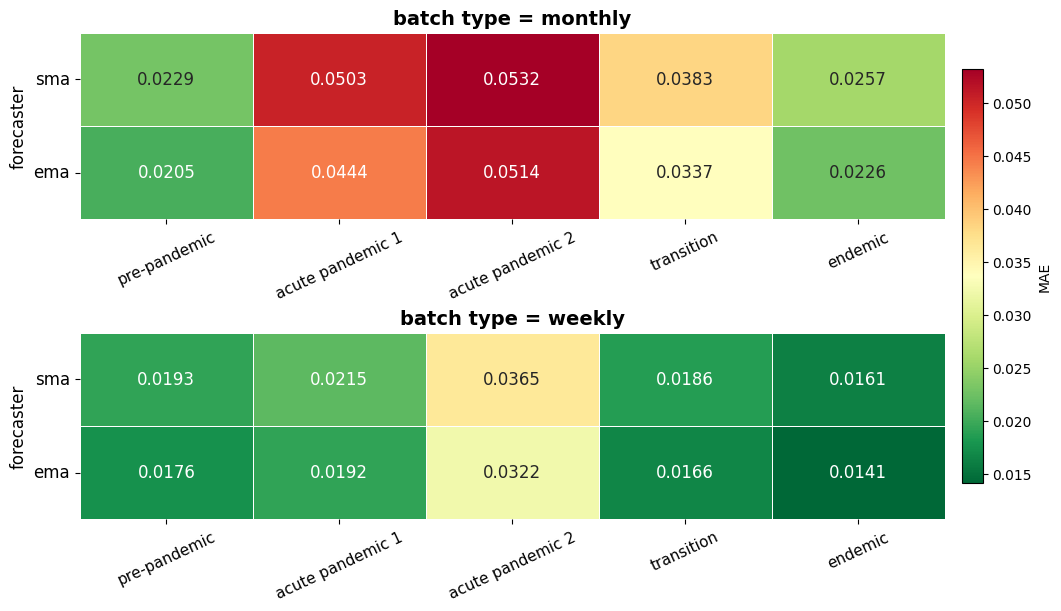

In [24]:
_FORECASTER_ORDER = ['sma', 'ema']
_BT_ORDER = ['monthly', 'weekly']

mae_agg_bt = (
    fq_df.groupby(['batch_type', 'forecaster', 'period'], observed=True)['abs_error']
    .mean()
    .rename('mae_mean')
    .reset_index()
)
vmin = float(mae_agg_bt['mae_mean'].min())
vmax = float(mae_agg_bt['mae_mean'].max())

fig, axes = plt.subplots(len(_BT_ORDER), 1, figsize=(1.7 * len(PERIOD_ORDER_EN) + 2, 3.0 * len(_BT_ORDER)),
                         squeeze=False, layout='constrained')
for r, bt in enumerate(_BT_ORDER):
    ax = axes[r][0]
    mat = (
        mae_agg_bt[mae_agg_bt['batch_type'] == bt]
        .pivot(index='forecaster', columns='period', values='mae_mean')
        .reindex(index=_FORECASTER_ORDER, columns=PERIOD_ORDER_EN)
    )
    sns.heatmap(mat, annot=True, fmt='.4f', cmap='RdYlGn_r', ax=ax, vmin=vmin, vmax=vmax, cbar=False,
                linewidths=0.5, linecolor='white', annot_kws={'fontsize': 12})
    ax.set_title(f'batch type = {bt}', fontsize=14, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('forecaster', fontsize=12)
    ax.tick_params(axis='x', rotation=25, labelsize=11)
    ax.tick_params(axis='y', rotation=0, labelsize=12)

# Colorbar única compartilhada pelos painéis
sm = mpl.cm.ScalarMappable(cmap='RdYlGn_r', norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax))
fig.colorbar(sm, ax=axes, label='MAE', shrink=0.85, pad=0.02)
save_fig(fig, 'fig08_mae_by_period.png')

#### Fig. 8b — versão combinada (um heatmap, forecaster × batch type)

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\artigo\fig08b_mae_by_period_combined.png


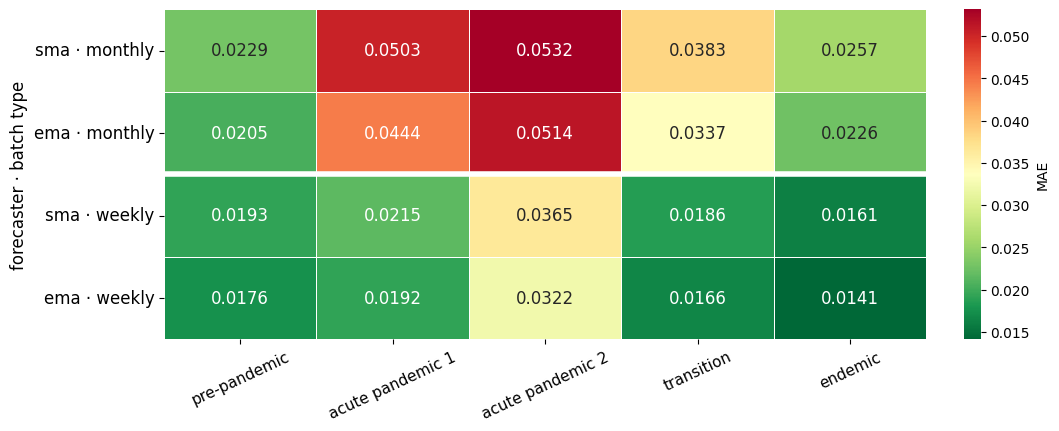

In [25]:
# Sem pooling: MAE mensal e semanal não estão na mesma escala; as 4 linhas ficam lado a lado
mat = (
    mae_agg_bt.assign(row=mae_agg_bt['forecaster'] + ' · ' + mae_agg_bt['batch_type'])
    .pivot(index='row', columns='period', values='mae_mean')
    .reindex(index=[f'{fk} · {bt}' for bt in BT_ORDER for fk in _FORECASTER_ORDER], columns=PERIOD_ORDER_EN)
)

fig, ax = plt.subplots(figsize=(1.7 * len(PERIOD_ORDER_EN) + 2, 4.2), layout='constrained')
sns.heatmap(mat, annot=True, fmt='.4f', cmap='RdYlGn_r', ax=ax, vmin=vmin, vmax=vmax,
            linewidths=0.5, linecolor='white', annot_kws={'fontsize': 12}, cbar_kws={'label': 'MAE'})
ax.axhline(len(_FORECASTER_ORDER), color='white', linewidth=4)  # separa monthly de weekly
ax.set_xlabel('')
ax.set_ylabel('forecaster · batch type', fontsize=12)
ax.tick_params(axis='x', rotation=25, labelsize=11)
ax.tick_params(axis='y', rotation=0, labelsize=12)
save_fig(fig, 'fig08b_mae_by_period_combined.png')

### Fig. 9 — Forecast SMA/EMA × valor real

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\artigo\fig09_forecast_vs_real.png


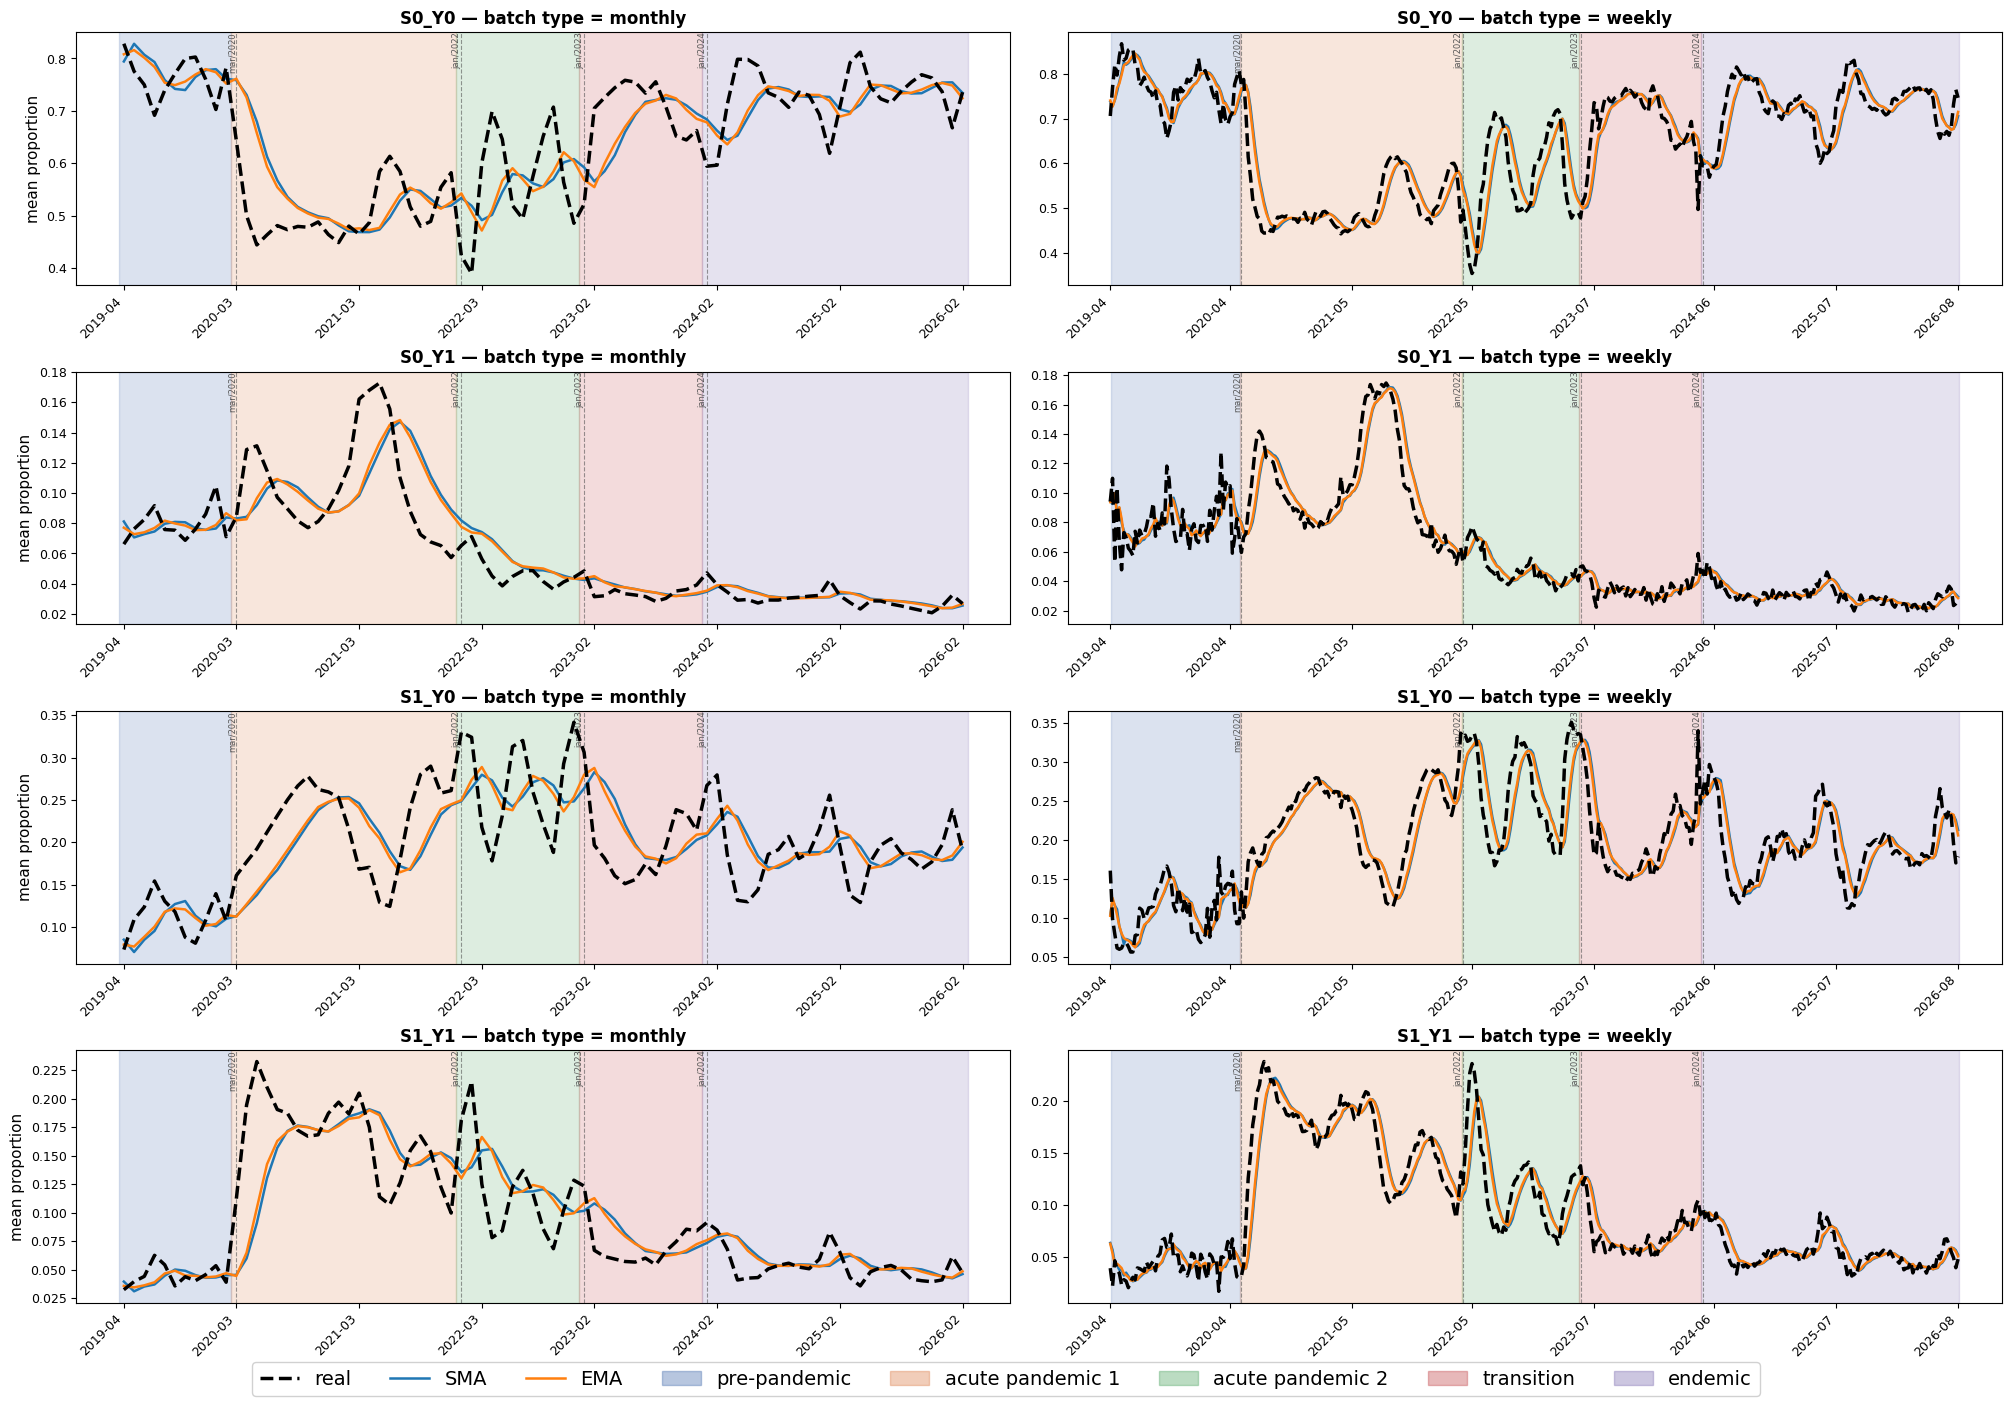

In [26]:
_PROPORTIONS = ['S0_Y0', 'S0_Y1', 'S1_Y0', 'S1_Y1']
_FORECASTER_STYLE = {'sma': '#1f77b4', 'ema': '#ff7f0e'}

# forecast: média sobre as janelas (mantém proporção/forecaster separados)
fc = fq_df.groupby(['batch_type', 'proportion', 'forecaster', 'batch'], as_index=False)['forecast_value'].mean()
# real: idêntico entre forecasters/janelas
rv = fq_df.groupby(['batch_type', 'proportion', 'batch'], as_index=False)['real_value'].mean()

fig, axes = plt.subplots(len(_PROPORTIONS), len(_BT_ORDER), figsize=(20, 14), squeeze=False, layout='constrained')
period_handles = []
for r, prop in enumerate(_PROPORTIONS):
    for c, bt in enumerate(_BT_ORDER):
        ax = axes[r][c]
        all_batch_labels = sorted(fq_df[fq_df['batch_type'] == bt]['batch'].astype(str).unique())
        xpos = {b: i for i, b in enumerate(all_batch_labels)}

        ph = _add_period_spans(ax, all_batch_labels, bt)
        if not period_handles:
            period_handles = ph

        # valor real (preto tracejado, mais espesso)
        rsub = rv[(rv['batch_type'] == bt) & (rv['proportion'] == prop)].copy()
        rsub['x'] = rsub['batch'].astype(str).map(xpos)
        rsub = rsub.sort_values('x')
        ax.plot(rsub['x'], rsub['real_value'], color='black', linestyle='--', linewidth=2.5, label='real', zorder=4)

        # forecasts SMA e EMA (sólidos)
        for fk in _FORECASTER_ORDER:
            fsub = fc[(fc['batch_type'] == bt) & (fc['proportion'] == prop) & (fc['forecaster'] == fk)].copy()
            fsub['x'] = fsub['batch'].astype(str).map(xpos)
            fsub = fsub.sort_values('x')
            ax.plot(fsub['x'], fsub['forecast_value'], color=_FORECASTER_STYLE[fk],
                    linewidth=1.8, label=fk.upper(), zorder=3)

        ax.set_title(f'{prop} — batch type = {bt}', fontsize=12, fontweight='bold')
        if c == 0:
            ax.set_ylabel('mean proportion', fontsize=11)
        _apply_bin_xticks(ax, all_batch_labels, n_bins=8)
        ax.tick_params(axis='x', labelsize=9)
        ax.tick_params(axis='y', labelsize=9)

# Sombreamento de período mais suave (identidade do projeto)
for ax in fig.axes:
    for patch in ax.patches:
        patch.set_alpha(0.20)

# Legenda única: séries (só as linhas; as faixas entram via period_handles) + períodos em inglês
series_handles = axes[0][0].get_lines()
series_handles = [h for h in series_handles if not h.get_label().startswith('_')]
leg = fig.legend(series_handles + period_handles,
                 [h.get_label() for h in series_handles]
                 + [PERIOD_LABELS_EN.get(h.get_label(), h.get_label()) for h in period_handles],
                 loc='outside lower center', ncol=len(series_handles) + len(period_handles),
                 fontsize=14, framealpha=0.9)
for lp in leg.get_patches():
    lp.set_alpha(0.4)
save_fig(fig, 'fig09_forecast_vs_real.png', dpi=150)

#### Fig. 9b — versão combinada (real e EMA, monthly e weekly no mesmo eixo)

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\artigo\fig09b_forecast_vs_real_combined.png


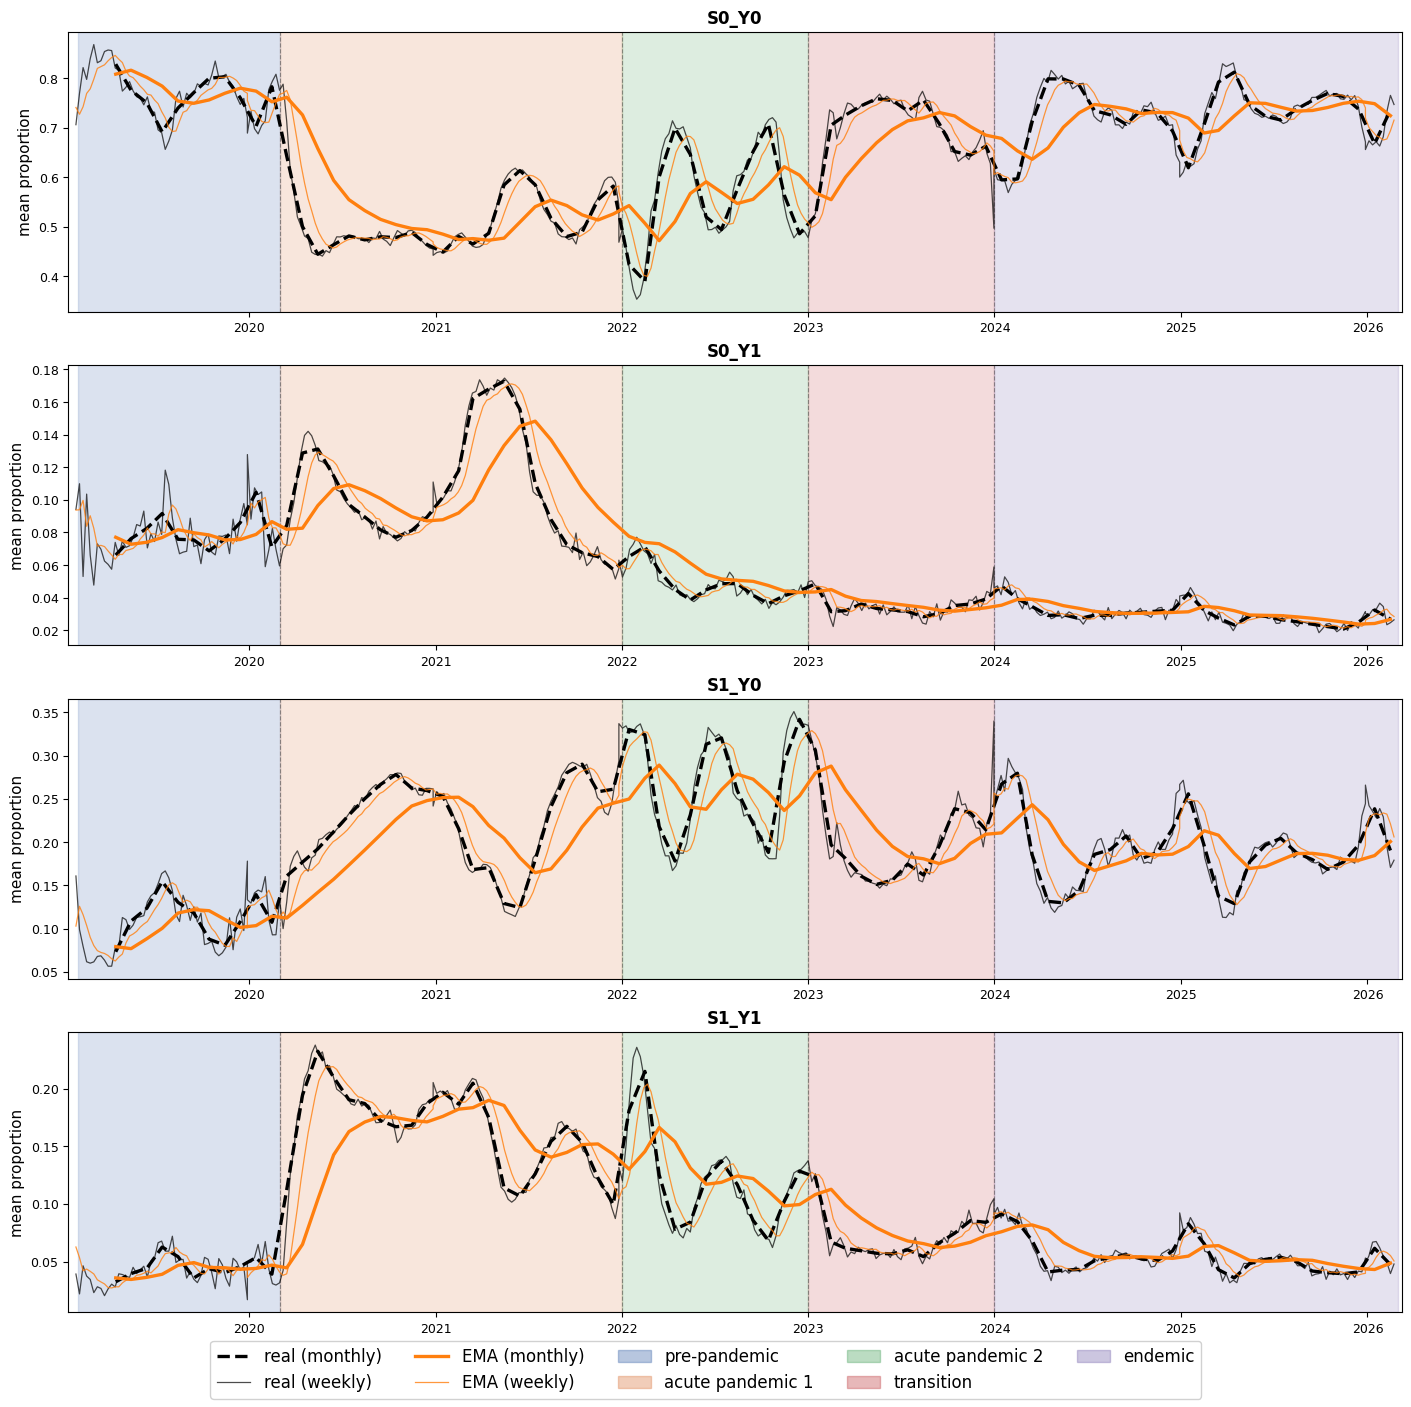

In [27]:
# Cor = série (real preto, EMA laranja); batch type = espessura: monthly grosso, weekly fino.
# SMA fica de fora (quase coincide com o EMA); monthly no meio do mês (ver batch_dates).
_SERIES_9B = [
    ('real', 'monthly', rv, 'real_value', dict(color='black', linewidth=2.4, linestyle='--')),
    ('real', 'weekly', rv, 'real_value', dict(color='black', linewidth=0.9, alpha=0.7)),
    ('EMA', 'monthly', fc[fc['forecaster'] == 'ema'], 'forecast_value', dict(color='#ff7f0e', linewidth=2.4)),
    ('EMA', 'weekly', fc[fc['forecaster'] == 'ema'], 'forecast_value', dict(color='#ff7f0e', linewidth=0.9, alpha=0.8)),
]

fig, axes = plt.subplots(len(_PROPORTIONS), 1, figsize=(14, 14), squeeze=False, layout='constrained')
all_dates = []
for r, prop in enumerate(_PROPORTIONS):
    ax = axes[r][0]
    period_handles = add_period_spans_dt(ax)
    series_handles = []
    for name, bt, src, col, style in _SERIES_9B:
        sub = src[(src['batch_type'] == bt) & (src['proportion'] == prop)].copy()
        sub['dt'] = batch_dates(sub['batch'], bt)
        sub = sub.sort_values('dt')
        all_dates.extend(sub['dt'])
        line, = ax.plot(sub['dt'], sub[col], label=f'{name} ({bt})', zorder=3, **style)
        series_handles.append(line)
    ax.set_title(prop, fontsize=12, fontweight='bold')
    ax.set_ylabel('mean proportion', fontsize=11)
    ax.tick_params(axis='both', labelsize=9)

for ax in fig.axes:
    fmt_date_axis(ax, all_dates)

leg = fig.legend(series_handles + period_handles, [h.get_label() for h in series_handles + period_handles],
                 loc='outside lower center', ncol=5, fontsize=12, framealpha=0.9)
for lp in leg.get_patches():
    lp.set_alpha(0.4)
save_fig(fig, 'fig09b_forecast_vs_real_combined.png', dpi=150)

### Fig. 10 — SMA × EMA × Oracle no XGBoost

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\artigo\fig10_forecasting_xgboost.png


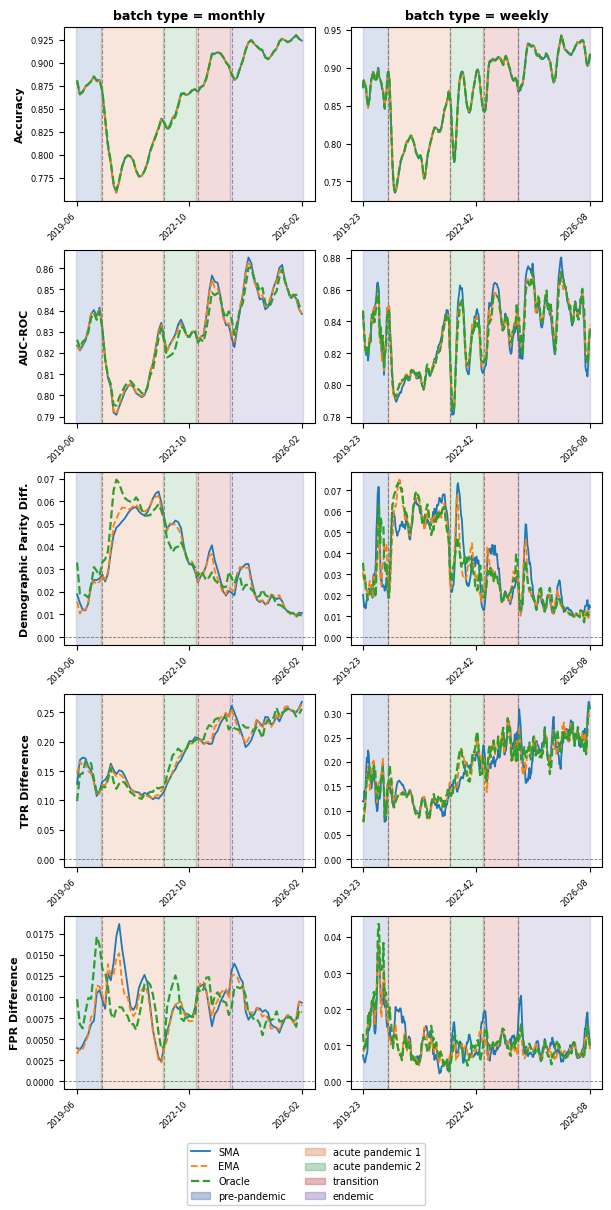

In [28]:
# Mesmo horizonte para as 3 técnicas (forecast_window == 5)
abc3 = load_filtered('assessment_all_baselines.csv', ['xgboost'], technique=['sma', 'ema', 'oracle'])
abc3 = abc3[(abc3['baseline'] == 'abcinml') & (abc3['forecast_window'] == 5)].copy()

_TECH_STYLE3 = {
    'sma': ('#1f77b4', '-', 1.3),
    'ema': ('#ff7f0e', '--', 1.3),
    'oracle': ('#2ca02c', '--', 1.6),   # verde tracejado mais espesso = teto teórico
}
_TECH_LABEL3 = {'sma': 'SMA', 'ema': 'EMA', 'oracle': 'Oracle'}


def _plot_triple_metric(ax, model, bt, col, is_fairness):
    sub_mb = abc3[(abc3['model_name'] == model) & (abc3['batch_type'] == bt)]
    all_batch_labels = sorted(sub_mb['batch'].astype(str).unique())
    ph = _add_period_spans(ax, all_batch_labels, bt)
    if is_fairness:
        ax.axhline(y=0, color='black', linestyle='--', linewidth=0.6, alpha=0.5, zorder=2)
    line_handles = {}
    for tech, (color, ls, lw) in _TECH_STYLE3.items():
        s = sub_mb[sub_mb['forecasting_technique'] == tech]
        per_batch = s.groupby(s['batch'].astype(str))[col].mean()
        per_batch = per_batch.reindex([b for b in all_batch_labels if b in per_batch.index])
        ma = per_batch.rolling(window=5, min_periods=1).mean()
        x = [all_batch_labels.index(b) for b in ma.index]
        line, = ax.plot(x, ma.values, color=color, linestyle=ls, linewidth=lw, label=_TECH_LABEL3[tech], zorder=3)
        line_handles[tech] = line
    _apply_bin_xticks(ax, all_batch_labels, n_bins=3)
    ax.tick_params(axis='x', labelsize=6)
    ax.tick_params(axis='y', labelsize=6)
    return line_handles, ph


def make_triple_figure(model):
    # Linhas = métricas, colunas = batch_type; coluna estreita para meia página de artigo
    fig, axes = plt.subplots(len(ARTICLE_METRICS), len(_BT_ORDER), figsize=(6, 12), squeeze=False, layout='constrained')
    line_handles, period_handles = {}, []
    for r, (col, label) in enumerate(ARTICLE_METRICS):
        for c, bt in enumerate(_BT_ORDER):
            ax = axes[r][c]
            lh, ph = _plot_triple_metric(ax, model, bt, col, col in ('dp', 'tpr_diff', 'fpr_diff'))
            line_handles.update(lh)
            if not period_handles:
                period_handles = ph
            if r == 0:
                ax.set_title(f'batch type = {bt}', fontsize=9, fontweight='bold')
            if c == 0:
                ax.set_ylabel(label, fontsize=8, fontweight='bold')

    # Sombreamento de período mais suave (sem rótulos de vline)
    for ax in fig.axes:
        for patch in ax.patches:
            patch.set_alpha(0.20)
        for text in ax.texts:
            text.set_visible(False)

    all_handles = [line_handles[t] for t in _TECH_STYLE3] + period_handles
    all_labels = list(_TECH_LABEL3.values()) + [PERIOD_LABELS_EN.get(h.get_label(), h.get_label()) for h in period_handles]
    leg = fig.legend(all_handles, all_labels, loc='outside lower center', ncol=2, fontsize=7, framealpha=0.9)
    for lp in leg.get_patches():
        lp.set_alpha(0.4)
    return fig


save_fig(make_triple_figure('xgboost'), 'fig10_forecasting_xgboost.png', dpi=150)

#### Fig. 10b — versão combinada (monthly e weekly no mesmo eixo)

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\artigo\fig10b_forecasting_xgboost_combined.png


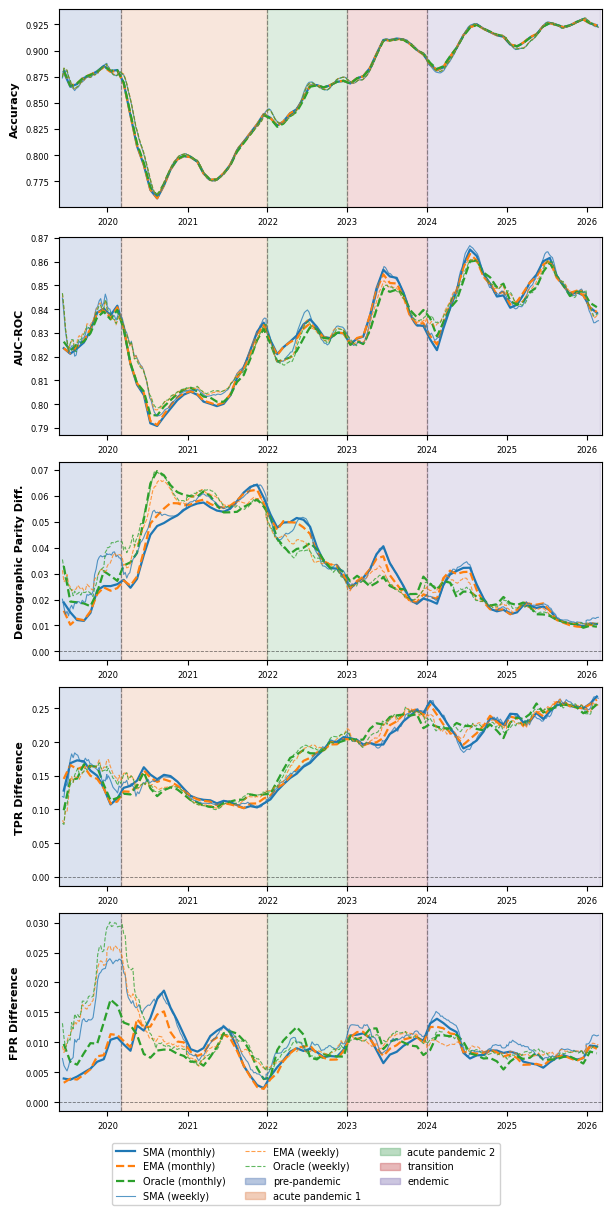

In [29]:
# Cor = técnica (como na Fig. 10); batch type = espessura: monthly grosso, weekly fino.
# Média móvel de 5 meses vs. 20 semanas (mesmo intervalo de tempo); a Fig. 10 usa 5 batches nos dois.
_BT_STYLE_10B = {'monthly': dict(linewidth=1.6), 'weekly': dict(linewidth=0.8, alpha=0.75)}


def make_triple_figure_combined(model):
    fig, axes = plt.subplots(len(ARTICLE_METRICS), 1, figsize=(6, 12), squeeze=False, layout='constrained')
    handles, period_handles, all_dates = [], [], []
    for r, (col, label) in enumerate(ARTICLE_METRICS):
        ax = axes[r][0]
        ph = add_period_spans_dt(ax)
        period_handles = period_handles or ph
        if col in ('dp', 'tpr_diff', 'fpr_diff'):
            ax.axhline(y=0, color='black', linestyle='--', linewidth=0.6, alpha=0.5, zorder=2)
        for bt in BT_ORDER:
            for tech, (color, ls, _) in _TECH_STYLE3.items():
                s = abc3[(abc3['model_name'] == model) & (abc3['batch_type'] == bt)
                         & (abc3['forecasting_technique'] == tech)]
                per_batch = s.groupby(s['batch'].astype(str))[col].mean().sort_index()
                ma = per_batch.rolling(window=MA_WINDOW_COMBINED[bt], min_periods=1).mean()
                dts = batch_dates(ma.index, bt)
                all_dates.extend(dts)
                line, = ax.plot(dts, ma.values, color=color, linestyle=ls, zorder=3,
                                label=f'{_TECH_LABEL3[tech]} ({bt})', **_BT_STYLE_10B[bt])
                if r == 0:
                    handles.append(line)
        ax.set_ylabel(label, fontsize=8, fontweight='bold')
        ax.tick_params(axis='both', labelsize=6)

    for ax in fig.axes:
        fmt_date_axis(ax, all_dates)

    leg = fig.legend(handles + period_handles, [h.get_label() for h in handles + period_handles],
                     loc='outside lower center', ncol=3, fontsize=7, framealpha=0.9)
    for lp in leg.get_patches():
        lp.set_alpha(0.4)
    return fig


save_fig(make_triple_figure_combined('xgboost'), 'fig10b_forecasting_xgboost_combined.png', dpi=150)